In [1]:
"""
Lightweight polyp segmentation on Kvasir-SEG (TensorFlow / Keras, .keras output)
- Depthwise-separable U-Net (CNN) -> Grad-CAM / Score-CAM / feature maps
- 80 / 10 / 10 split, live progress %, all metrics every epoch, best-model saving,
  test metrics, FPS benchmark, budget check, XAI figures

pip install "tensorflow>=2.13" numpy opencv-python matplotlib tqdm
"""

'\nLightweight polyp segmentation on Kvasir-SEG (TensorFlow / Keras, .keras output)\n- Depthwise-separable U-Net (CNN) -> Grad-CAM / Score-CAM / feature maps\n- 80 / 10 / 10 split, live progress %, all metrics every epoch, best-model saving,\n  test metrics, FPS benchmark, budget check, XAI figures\n\npip install "tensorflow>=2.13" numpy opencv-python matplotlib tqdm\n'

In [2]:
import os, json, random, math, time, csv
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, Model
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from tqdm import tqdm


I0000 00:00:1792047048.510025   11283 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# ============================ USER PATHS ============================
IMG_DIR   = r"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images"
MASK_DIR  = r"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks"
SAVE_PATH = r"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/micromodel_v2.keras"  # must end with .keras

In [4]:
USE_MIXED_PRECISION = False           # tiny model: no real speedup; keep False
FAST_STEM  = True                     # True: half-resolution stem (much faster, ~0.5-1% lower Dice); False: full-res
IMG_SIZE   = 256                      # must be divisible by 32 (FAST_STEM) or 16
CHANNELS   = (32, 64, 96, 128, 192)
EPOCHS     = 100
BATCH_SIZE = 4
MAX_LR     = 3e-3
WEIGHT_DECAY = 1e-4
PATIENCE   = 40
SEED       = 42
N_XAI_IMAGES = 8

TARGETS = dict(gmacs=1.0, params_m=0.5, size_mb=2.0, metric=0.95, fps=50.0)

In [5]:
assert SAVE_PATH.endswith(".keras"), "SAVE_PATH must end with .keras"
assert IMG_SIZE % (32 if FAST_STEM else 16) == 0, "IMG_SIZE must be divisible by 32 (FAST_STEM) or 16"
BASE = SAVE_PATH[:-len(".keras")]
STEM_STRIDE = 2 if FAST_STEM else 1
UP_MODE = "nearest" if USE_MIXED_PRECISION else "bilinear"
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
AUTOTUNE = tf.data.AUTOTUNE
METRIC_KEYS = ["dice", "iou", "precision", "recall", "specificity", "accuracy"]


In [6]:
def seed_everything(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)


# ------------------------------- MODEL -------------------------------
def dsconv(x, cout, name, last=False):
    # depthwise 3x3 + pointwise 1x1 (SeparableConv2D), BN, ReLU
    x = layers.SeparableConv2D(cout, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU(name=f"{name}_out" if last else None)(x)


def block(x, cout, name):
    x = dsconv(x, cout, name)
    return dsconv(x, cout, name, last=True)

In [7]:
def build_model(ch=CHANNELS, size=IMG_SIZE):
    c0, c1, c2, c3, c4 = ch
    inp = layers.Input((size, size, 3))
    x = layers.Conv2D(c0, 3, strides=STEM_STRIDE, padding="same", use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(name="stem_out")(x)

    s0 = block(x, c0, "enc1")
    s1 = block(layers.MaxPool2D()(s0), c1, "enc2")
    s2 = block(layers.MaxPool2D()(s1), c2, "enc3")
    s3 = block(layers.MaxPool2D()(s2), c3, "enc4")
    b  = block(layers.MaxPool2D()(s3), c4, "bott")

    up = lambda t: layers.UpSampling2D(2, interpolation=UP_MODE)(t)
    d3 = block(layers.Concatenate()([up(b),  s3]), c3, "dec4")
    d2 = block(layers.Concatenate()([up(d3), s2]), c2, "dec3")
    d1 = block(layers.Concatenate()([up(d2), s1]), c1, "dec2")
    d0 = block(layers.Concatenate()([up(d1), s0]), c0, "dec1")

    if FAST_STEM:   # predict at half resolution, then upsample the logits to full size
        out = layers.Conv2D(1, 1, dtype="float32", name="head")(d0)
        out = layers.UpSampling2D(2, interpolation=UP_MODE, dtype="float32", name="logits")(out)
    else:
        out = layers.Conv2D(1, 1, dtype="float32", name="logits")(d0)
    return Model(inp, out, name="LiteUNet")

In [8]:
def count_params(m):
    return m.count_params() / 1e6

In [9]:
def count_gmacs(model):
    macs = 0
    for l in model.layers:
        if isinstance(l, layers.SeparableConv2D):
            h, w, cout = l.output.shape[1:4]; cin = l.input.shape[-1]; k = l.kernel_size[0]
            macs += h * w * cin * k * k + h * w * cin * cout
        elif isinstance(l, layers.Conv2D):
            h, w, cout = l.output.shape[1:4]; cin = l.input.shape[-1]; k = l.kernel_size[0]
            macs += h * w * cout * cin * k * k
    return macs / 1e9

In [10]:
# ------------------------------- DATA --------------------------------
def build_splits(img_dir, mask_dir, seed=SEED):
    exts = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
    imgs  = sorted(f for f in os.listdir(img_dir) if f.lower().endswith(exts))
    masks = {os.path.splitext(f)[0]: f for f in os.listdir(mask_dir) if f.lower().endswith(exts)}
    pairs = [(os.path.join(img_dir, f), os.path.join(mask_dir, masks[os.path.splitext(f)[0]]))
             for f in imgs if os.path.splitext(f)[0] in masks]
    assert pairs, "No image/mask pairs found - check paths and filenames."
    rng = random.Random(seed); rng.shuffle(pairs)
    n = len(pairs); n_tr = int(0.8 * n); n_va = int(0.1 * n)
    return pairs[:n_tr], pairs[n_tr:n_tr + n_va], pairs[n_tr + n_va:]

In [11]:
def load_pair(ip, mp):
    img = cv2.imread(ip); msk = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    assert img is not None, f"Cannot read image: {ip}"
    assert msk is not None, f"Cannot read mask: {mp}"
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    msk = cv2.resize(msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return img, (msk > 127).astype(np.uint8)

In [12]:
def load_split(pairs, desc):
    data = [load_pair(ip, mp) for ip, mp in tqdm(pairs, desc=desc, leave=False)]
    return np.stack([d[0] for d in data]), np.stack([d[1] for d in data])


def normalize(img):
    return (img.astype(np.float32) / 255.0 - MEAN) / STD

In [13]:
def augment(img, msk):
    if random.random() < 0.5: img, msk = img[:, ::-1], msk[:, ::-1]
    if random.random() < 0.5: img, msk = img[::-1], msk[::-1]
    k = random.randint(0, 3)
    img, msk = np.rot90(img, k), np.rot90(msk, k)
    img, msk = np.ascontiguousarray(img), np.ascontiguousarray(msk)
    if random.random() < 0.7:
        h, w = msk.shape
        M = cv2.getRotationMatrix2D((w / 2, h / 2), random.uniform(-30, 30), random.uniform(0.85, 1.2))
        M[:, 2] += (random.uniform(-0.1, 0.1) * w, random.uniform(-0.1, 0.1) * h)
        img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
        msk = cv2.warpAffine(msk, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT)
    if random.random() < 0.7:
        img = np.clip(img.astype(np.float32) * random.uniform(0.8, 1.2) + random.uniform(-20, 20), 0, 255).astype(np.uint8)
    if random.random() < 0.3:
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.int16)
        hsv[..., 0] = (hsv[..., 0] + random.randint(-8, 8)) % 180
        hsv[..., 1] = np.clip(hsv[..., 1] + random.randint(-20, 20), 0, 255)
        img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    return img, msk

In [14]:
def make_train_ds(imgs, msks):
    def fetch(i):
        img, msk = augment(imgs[i], msks[i])
        return normalize(img), msk.astype(np.float32)[..., None]

    def tf_fetch(i):
        x, y = tf.numpy_function(fetch, [i], [tf.float32, tf.float32])
        x.set_shape((IMG_SIZE, IMG_SIZE, 3)); y.set_shape((IMG_SIZE, IMG_SIZE, 1))
        return x, y

    n = len(imgs)
    return (tf.data.Dataset.range(n).shuffle(n, reshuffle_each_iteration=True)
            .map(tf_fetch, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE, drop_remainder=True).prefetch(AUTOTUNE))

In [15]:
def prep_eval(imgs, msks):
    x = np.stack([normalize(i) for i in imgs])
    y = msks.astype(np.float32)[..., None]
    return x, y


# --------------------------- LOSS / METRICS --------------------------
def seg_loss(y_true, logits):
    y_true = tf.cast(y_true, tf.float32); logits = tf.cast(logits, tf.float32)
    bce = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(labels=y_true, logits=logits))
    p = tf.reshape(tf.sigmoid(logits), (tf.shape(logits)[0], -1))
    g = tf.reshape(y_true, (tf.shape(logits)[0], -1))
    d = 1.0 - (2 * tf.reduce_sum(p * g, 1) + 1.0) / (tf.reduce_sum(p, 1) + tf.reduce_sum(g, 1) + 1.0)
    return bce + tf.reduce_mean(d)


def _bin(logits):
    return tf.cast(tf.sigmoid(tf.cast(logits, tf.float32)) > 0.5, tf.float32)


def dice(y_true, y_pred):          # Keras training metric (per-sample Dice, averaged)
    p, g = _bin(y_pred), tf.cast(y_true, tf.float32)
    tp = tf.reduce_sum(p * g, (1, 2, 3))
    s = tf.reduce_sum(p, (1, 2, 3)) + tf.reduce_sum(g, (1, 2, 3))
    return tf.reduce_mean((2 * tp + 1e-7) / (s + 1e-7))


def iou(y_true, y_pred):           # Keras training metric (per-sample IoU, averaged)
    p, g = _bin(y_pred), tf.cast(y_true, tf.float32)
    tp = tf.reduce_sum(p * g, (1, 2, 3))
    u = tf.reduce_sum(p, (1, 2, 3)) + tf.reduce_sum(g, (1, 2, 3)) - tp
    return tf.reduce_mean((tp + 1e-7) / (u + 1e-7))

In [16]:
def batch_metrics(logits, gt, thr=0.5, eps=1e-7):
    logits = np.clip(logits.astype(np.float64), -50, 50)
    p = (1 / (1 + np.exp(-logits)) > thr).astype(np.float64).reshape(len(gt), -1)
    g = gt.astype(np.float64).reshape(len(gt), -1)
    tp = (p * g).sum(1); fp = (p * (1 - g)).sum(1); fn = ((1 - p) * g).sum(1); tn = ((1 - p) * (1 - g)).sum(1)
    return {
        "dice":        (2 * tp + eps) / (2 * tp + fp + fn + eps),
        "iou":         (tp + eps) / (tp + fp + fn + eps),
        "precision":   (tp + eps) / (tp + fp + eps),
        "recall":      (tp + eps) / (tp + fn + eps),
        "specificity": (tn + eps) / (tn + fp + eps),
        "accuracy":    (tp + tn) / (tp + tn + fp + fn),
    }


def evaluate(model, x, y):
    logits = model.predict(x, batch_size=32, verbose=0)
    res = {k: float(v.mean()) for k, v in batch_metrics(logits, y).items()}
    res["loss"] = float(seg_loss(y, logits).numpy())
    return res


# ------------------------------ TRAINING -----------------------------
class OneCycle(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, max_lr, total_steps, pct=0.1, div=25.0, final=1e-6):
        super().__init__()
        self.max_lr, self.total, self.pct, self.div, self.final = max_lr, total_steps, pct, div, final

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = float(self.total) * self.pct
        start = self.max_lr / self.div
        lr_w = start + (self.max_lr - start) * step / warm
        prog = tf.clip_by_value((step - warm) / (float(self.total) - warm), 0.0, 1.0)
        lr_c = self.final + (self.max_lr - self.final) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        return tf.where(step < warm, lr_w, lr_c)

    def get_config(self):
        return dict(max_lr=self.max_lr, total_steps=self.total, pct=self.pct, div=self.div, final=self.final)


class TrainMonitor(tf.keras.callbacks.Callback):
    """Progress %, ETA, all metrics every epoch, CSV log, best-model (.keras) saving, early stopping."""
    def __init__(self, xv, yv, steps_per_epoch, sched):
        super().__init__()
        self.xv, self.yv, self.spe, self.sched = xv, yv, steps_per_epoch, sched
        self.best, self.bad = -1.0, 0
        self.export = build_model()          # clean, optimizer-free copy used for saving
        self.csv_path = BASE + "_log.csv"

    def on_train_begin(self, logs=None):
        self.t_start = time.time()
        with open(self.csv_path, "w", newline="") as f:
            csv.writer(f).writerow(["epoch", "lr", "train_loss", "train_dice", "train_iou", "val_loss"]
                                   + [f"val_{k}" for k in METRIC_KEYS] + ["best_val_dice"])

    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()
        pct = 100.0 * epoch / EPOCHS
        self.pbar = tqdm(total=self.spe, desc=f"Ep {epoch+1:03d}/{EPOCHS} [{pct:5.1f}%]",
                         leave=False, ncols=100)

    def on_train_batch_end(self, batch, logs=None):
        self.pbar.update(1)
        if logs:
            self.pbar.set_postfix(loss=f"{logs.get('loss', 0.0):.4f}")

    def on_epoch_end(self, epoch, logs=None):
        self.pbar.close()
        logs = logs or {}
        v = evaluate(self.model, self.xv, self.yv)
        done = epoch + 1
        pct = 100.0 * done / EPOCHS
        elapsed = time.time() - self.t_start
        eta = elapsed / done * (EPOCHS - done)
        lr = float(self.sched(tf.constant(done * self.spe, dtype=tf.float32)))

        improved = v["dice"] > self.best
        if improved:
            self.best, self.bad = v["dice"], 0
            self.export.set_weights(self.model.get_weights())
            self.export.save(SAVE_PATH)                      # best model, .keras
        else:
            self.bad += 1

        print(f"[Ep {done:03d}/{EPOCHS} | {pct:5.1f}%] {time.time()-self.t0:5.1f}s | "
              f"ETA {eta/60:6.1f} min | lr {lr:.2e}")
        print(f"   train: loss {logs.get('loss', float('nan')):.4f} | "
              f"dice {logs.get('dice', float('nan')):.4f} | iou {logs.get('iou', float('nan')):.4f}")
        print(f"   val  : loss {v['loss']:.4f} | dice {v['dice']:.4f} | iou {v['iou']:.4f} | "
              f"prec {v['precision']:.4f} | rec {v['recall']:.4f} | "
              f"spec {v['specificity']:.4f} | acc {v['accuracy']:.4f}")
        print(f"   best val dice {self.best:.4f}" + ("  <-- new best, model saved" if improved
                                                      else f"  (no gain for {self.bad}/{PATIENCE})"))

        with open(self.csv_path, "a", newline="") as f:
            csv.writer(f).writerow([done, lr, logs.get("loss"), logs.get("dice"), logs.get("iou"), v["loss"]]
                                   + [v[k] for k in METRIC_KEYS] + [self.best])

        if self.bad >= PATIENCE:
            print("Early stopping.")
            self.model.stop_training = True


# ------------------------------- FPS ---------------------------------
def _make_infer(model):
    @tf.function
    def infer(x):
        return tf.sigmoid(model(x, training=False))
    return infer


def measure_fps(model, batch=1, warmup=50, runs=300):
    infer = _make_infer(model)
    x = tf.constant(np.random.rand(batch, IMG_SIZE, IMG_SIZE, 3).astype(np.float32))
    for _ in range(warmup):
        infer(x).numpy()
    t0 = time.perf_counter()
    for _ in range(runs):
        infer(x).numpy()                       # .numpy() forces a device sync -> honest timing
    return batch * runs / (time.perf_counter() - t0)

def measure_fps_e2e(model, img_path, warmup=30, runs=200):
    """Full pipeline: resize + normalize + inference + threshold (on a real image)."""
    raw = cv2.imread(img_path)
    infer = _make_infer(model)

    def step():
        im = cv2.cvtColor(cv2.resize(raw, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB)
        x = tf.constant(normalize(im)[None])
        return infer(x).numpy()[0, ..., 0] > 0.5

    for _ in range(warmup):
        step()
    t0 = time.perf_counter()
    for _ in range(runs):
        step()
    return runs / (time.perf_counter() - t0)

# ------------------------------- MAIN --------------------------------
def train():
    seed_everything(SEED)
    os.makedirs(os.path.dirname(os.path.abspath(SAVE_PATH)), exist_ok=True)
    tr, va, te = build_splits(IMG_DIR, MASK_DIR)
    print(f"Split -> train {len(tr)} | val {len(va)} | test {len(te)}")
    with open(BASE + "_splits.json", "w") as f:
        json.dump({"train": tr, "val": va, "test": te}, f, indent=1)

    tr_i, tr_m = load_split(tr, "train"); va_i, va_m = load_split(va, "val"); te_i, te_m = load_split(te, "test")
    train_ds = make_train_ds(tr_i, tr_m)
    xv, yv = prep_eval(va_i, va_m)
    xt, yt = prep_eval(te_i, te_m)

    gpu = len(tf.config.list_physical_devices("GPU")) > 0
    print("Device:", "GPU" if gpu else "CPU (no GPU detected)")
    tf.keras.mixed_precision.set_global_policy("mixed_float16" if (gpu and USE_MIXED_PRECISION) else "float32")

    model = build_model()
    print(f"Params: {count_params(model):.4f} M | GMACs: {count_gmacs(model):.3f}")

    spe = len(tr_i) // BATCH_SIZE
    sched = OneCycle(MAX_LR, spe * EPOCHS)
    opt = tf.keras.optimizers.AdamW(sched, weight_decay=WEIGHT_DECAY, global_clipnorm=5.0)
    model.compile(optimizer=opt, loss=seg_loss, metrics=[dice, iou], jit_compile=False)
    model.fit(train_ds, epochs=EPOCHS, verbose=0, callbacks=[TrainMonitor(xv, yv, spe, sched)])

    # ---- reload the best saved .keras model and test it
    model = tf.keras.models.load_model(SAVE_PATH, compile=False)
    res = evaluate(model, xt, yt)
    params, gmacs = count_params(model), count_gmacs(model)
    size_mb = os.path.getsize(SAVE_PATH) / 1024 ** 2
    fps = measure_fps(model)
    fps_e2e = measure_fps_e2e(model, te[0][0])

    print("\n================ TEST RESULTS ================")
    rows = [("GMACs", gmacs, f"< {TARGETS['gmacs']}", gmacs < TARGETS["gmacs"]),
            ("Params (M)", params, f"<= {TARGETS['params_m']}", params <= TARGETS["params_m"]),
            ("Size (MB)", size_mb, f"< {TARGETS['size_mb']}", size_mb < TARGETS["size_mb"]),
            ("FPS (model)", fps, f">= {TARGETS['fps']:.0f}", fps >= TARGETS["fps"])]
    for k in METRIC_KEYS:
        rows.append((k, res[k], f"> {TARGETS['metric']}", res[k] > TARGETS["metric"]))
    for name, val, tgt, ok in rows:
        print(f"{name:<12} {val:10.4f}   target {tgt:<8}  {'PASS' if ok else 'FAIL'}")
    print(f"{'FPS (e2e)':<12} {fps_e2e:10.4f}   (resize + normalize + model + threshold)")
    out = {r[0]: float(r[1]) for r in rows}
    out["FPS (e2e)"] = float(fps_e2e)
    with open(BASE + "_test_metrics.json", "w") as f:
        json.dump(out, f, indent=1)

    explain(model, xt, yt, os.path.join(os.path.dirname(os.path.abspath(SAVE_PATH)), "xai"))

# --------------------------- EXPLAINABILITY --------------------------
def _norm(c):
    c = c - c.min()
    return c / (c.max() + 1e-8)
def _resize(t):  # (H,W,C) or (1,H,W,C) -> (IMG,IMG,C)
    t = t if t.shape.rank == 4 else t[None]
    return tf.image.resize(t, (IMG_SIZE, IMG_SIZE), method="bilinear")[0]
def grad_cam(model, x, layer_name):
    gm = Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        act, logits = gm(x, training=False)
        mask = tf.cast(tf.sigmoid(logits) > 0.5, tf.float32)
        if tf.reduce_sum(mask) == 0: mask = tf.ones_like(mask)
        target = tf.reduce_sum(logits * mask)
    grads = tape.gradient(target, act)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * act, -1, keepdims=True))
    return _norm(_resize(cam).numpy()[..., 0])
def score_cam(model, x, layer_name, chunk=32):
    gm = Model(model.inputs, [model.get_layer(layer_name).output, model.output])
    act, logits = gm(x, training=False)
    mask = tf.cast(tf.sigmoid(logits) > 0.5, tf.float32)
    if tf.reduce_sum(mask) == 0: mask = tf.ones_like(mask)
    up = _resize(act).numpy()                                       # H,W,C
    up = (up - up.min((0, 1), keepdims=True)) / (up.max((0, 1), keepdims=True) - up.min((0, 1), keepdims=True) + 1e-8)
    up = tf.constant(np.transpose(up, (2, 0, 1))[..., None].astype(np.float32))   # C,H,W,1
    scores = []
    for i in range(0, up.shape[0], chunk):
        p = tf.sigmoid(model(x * up[i:i + chunk], training=False))  # (chunk,H,W,1)
        scores.append(tf.reduce_sum(p * mask, (1, 2, 3)) / tf.reduce_sum(mask))
    w = tf.nn.softmax(tf.concat(scores, 0))                        # C
    cam = tf.nn.relu(tf.reduce_sum(w * act[0], -1, keepdims=True))  # h,w,1
    return _norm(_resize(cam).numpy()[..., 0])
def denorm(x):
    return np.clip(x * STD + MEAN, 0, 1)
def overlay(img, cam):
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1] / 255.0
    return np.clip(0.55 * img + 0.45 * heat, 0, 1)

In [17]:
def save_feature_maps(model, x, path, n=16, names=("stem_out", "enc2_out", "enc3_out", "dec3_out")):
    fm = Model(model.inputs, [model.get_layer(k).output for k in names])
    feats = [f[0].numpy() for f in fm(x, training=False)]
    fig, axes = plt.subplots(len(names), n, figsize=(n * 1.1, len(names) * 1.2))
    for r, (k, f) in enumerate(zip(names, feats)):
        for c in range(n):
            ax = axes[r, c]; ax.imshow(f[..., c], cmap="viridis"); ax.axis("off")
            if c == 0: ax.set_title(k, fontsize=7, loc="left")
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.close()


def explain(model, xs, ys, out_dir, layer_name="dec3_out"):
    os.makedirs(out_dir, exist_ok=True)
    idx = np.linspace(0, len(xs) - 1, min(N_XAI_IMAGES, len(xs))).astype(int)
    for j, i in enumerate(idx):
        x = xs[i][None]
        pred = (tf.sigmoid(model(x, training=False)).numpy()[0, ..., 0] > 0.5)
        img = denorm(xs[i])
        g, s = grad_cam(model, x, layer_name), score_cam(model, x, layer_name)
        fig, ax = plt.subplots(1, 5, figsize=(13, 2.8))
        for a, im, t in zip(ax, [img, ys[i][..., 0], pred, overlay(img, g), overlay(img, s)],
                            ["Image", "Ground truth", "Prediction", "Grad-CAM", "Score-CAM"]):
            a.imshow(im, cmap="gray" if im.ndim == 2 else None); a.set_title(t, fontsize=9); a.axis("off")
        plt.tight_layout(); plt.savefig(os.path.join(out_dir, f"cam_{j:02d}.png"), dpi=150); plt.close()
        if j == 0:
            save_feature_maps(model, x, os.path.join(out_dir, "feature_maps.png"))
    print(f"XAI figures saved to: {out_dir}")

In [18]:
if __name__ == "__main__":
    train()

Split -> train 800 | val 100 | test 100


W0000 00:00:1792052949.889174   11283 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.                                                                            
I0000 00:00:1792052949.889719   11283 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Device: GPU
Params: 0.2457 M | GMACs: 0.319


Ep 001/100 [  0.0%]:   0%|                                                  | 0/200 [00:00<?, ?it/s]I0000 00:00:1792052973.368488   71288 cuda_dnn.cc:461] Loaded cuDNN version 92101
                                                                                                    

[Ep 001/100 |   1.0%]  69.9s | ETA  114.5 min | lr 4.08e-04
   train: loss 1.2046 | dice 0.4254 | iou 0.2976
   val  : loss 1.3489 | dice 0.0000 | iou 0.0000 | prec 1.0000 | rec 0.0000 | spec 1.0000 | acc 0.8192
   best val dice 0.0000  <-- new best, model saved


...

[Ep 100/100 | 100.0%]  39.2s | ETA    0.0 min | lr 1.00e-06
   train: loss 0.2409 | dice 0.8846 | iou 0.8147
   val  : loss 0.3141 | dice 0.8545 | iou 0.7848 | prec 0.9202 | rec 0.8466 | spec 0.9845 | acc 0.9534
   best val dice 0.8614  (no gain for 27/40)


I0000 00:00:1792057078.365351   71287 service.cc:153] XLA service 0x7662b406aa60 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792057078.367540   71287 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1792057078.561019   71287 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792057098.746408   71287 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



================ TEST RESULTS ================
GMACs            0.3186   target < 1.0     PASS
Params (M)       0.2457   target <= 0.5    PASS
Size (MB)        1.1860   target < 2.0     PASS
FPS (model)     73.7159   target >= 50     PASS
dice             0.8727   target > 0.95    FAIL
iou              0.8028   target > 0.95    FAIL
precision        0.8677   target > 0.95    FAIL
recall           0.9121   target > 0.95    FAIL
specificity      0.9732   target > 0.95    PASS
accuracy         0.9637   target > 0.95    PASS
FPS (e2e)       62.9752   (resize + normalize + model + threshold)


/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/keras/src/models/functional.py:258: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_1']
Received: inputs=Tensor(shape=(1, 256, 256, 3))
  warnings.warn(msg)


XAI figures saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/xai


In [20]:
print("ok")

ok


In [21]:
"""
Paper figures for the Kvasir-SEG micromodel.

Reads what train() already wrote:
    <BASE>_log.csv        per-epoch metrics
    <BASE>_splits.json    train/val/test file lists
    <BASE>.keras          best model

Training curves (from the CSV, no model needed):
    loss, dice, iou, accuracy, all val metrics, lr, generalization gap, 2x2 overview
Evaluation figures (loads the model):
    train/val/test metric bars, pixel confusion matrix, ROC + PR, per-image Dice
    distribution, qualitative grid (best / median / worst)

pip install tensorflow numpy opencv-python matplotlib
"""
import os, csv, json
import numpy as np
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ============================ CONFIG ================================
BASE = r"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/micromodel_v2"
OUT_DIR = os.path.join(os.path.dirname(BASE), "figures")
IMG_SIZE = 256
RUN_EVAL_FIGURES = True        # False: only plot training curves from the CSV
N_ROC_PIXELS = 1_500_000       # pixel subsample for ROC / PR
SEED = 42
# ====================================================================

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)
C_TR, C_VA, C_TE, C_GR = "#1f6feb", "#e8590c", "#2f9e44", "#868e96"

plt.rcParams.update({
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "legend.frameon": False, "savefig.bbox": "tight",
})
os.makedirs(OUT_DIR, exist_ok=True)


def save(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name + ".png"), dpi=300)
    fig.savefig(os.path.join(OUT_DIR, name + ".pdf"))
    plt.close(fig)
    print("saved", name)


# ---------------------------- TRAINING CURVES -----------------------
def load_log(path):
    with open(path) as f:
        rows = list(csv.DictReader(f))
    cols = {}
    for k in rows[0]:
        cols[k] = np.array([float(r[k]) if r[k] not in ("", "None", "nan") else np.nan for r in rows])
    return cols


def draw_curve(ax, ep, series, ylabel, best_ep, title=None):
    for label, y, color, ls in series:
        ax.plot(ep, y, color=color, ls=ls, lw=1.8, label=label)
    ax.axvline(best_ep, color=C_GR, ls=":", lw=1.2, label=f"best epoch ({int(best_ep)})")
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    if title: ax.set_title(title)
    ax.legend(loc="best")


def single(ep, series, ylabel, best_ep, name, title=None):
    fig, ax = plt.subplots(figsize=(5.5, 3.8))
    draw_curve(ax, ep, series, ylabel, best_ep, title)
    save(fig, name)


def training_curves(log):
    ep = log["epoch"]
    best_ep = ep[np.nanargmax(log["val_dice"])]
    tr_va = lambda t, v: [("Train", log[t], C_TR, "-"), ("Validation", log[v], C_VA, "-")]

    single(ep, tr_va("train_loss", "val_loss"), "Loss (BCE + Dice)", best_ep, "fig_loss", "Training vs validation loss")
    single(ep, tr_va("train_dice", "val_dice"), "Dice coefficient", best_ep, "fig_dice", "Training vs validation Dice")
    single(ep, tr_va("train_iou", "val_iou"), "IoU", best_ep, "fig_iou", "Training vs validation IoU")

    has_tr_acc = "train_accuracy" in log and not np.all(np.isnan(log["train_accuracy"]))
    if has_tr_acc:
        acc_series = tr_va("train_accuracy", "val_accuracy")
        acc_title = "Training vs validation accuracy"
    else:
        acc_series = [("Validation", log["val_accuracy"], C_VA, "-")]
        acc_title = "Validation accuracy (train accuracy not logged)"
    single(ep, acc_series, "Pixel accuracy", best_ep, "fig_accuracy", acc_title)

    # all validation metrics together
    fig, ax = plt.subplots(figsize=(6, 4))
    cmap = plt.get_cmap("tab10")
    for i, k in enumerate(["dice", "iou", "precision", "recall", "specificity", "accuracy"]):
        ax.plot(ep, log[f"val_{k}"], lw=1.6, color=cmap(i), label=k.capitalize())
    ax.set_xlabel("Epoch"); ax.set_ylabel("Score"); ax.set_title("Validation metrics")
    ax.legend(ncol=3, loc="lower right")
    save(fig, "fig_val_metrics")

    # learning rate
    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    ax.plot(ep, log["lr"], color=C_TR, lw=1.8)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Learning rate"); ax.set_title("One-cycle learning-rate schedule")
    save(fig, "fig_lr")

    # generalization gap
    fig, ax = plt.subplots(figsize=(5.5, 3.2))
    ax.plot(ep, log["train_dice"] - log["val_dice"], color=C_GR, lw=1.8)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Train Dice - Val Dice"); ax.set_title("Generalization gap")
    save(fig, "fig_gap")

    # 2x2 overview
    fig, axs = plt.subplots(2, 2, figsize=(10, 7))
    draw_curve(axs[0, 0], ep, tr_va("train_loss", "val_loss"), "Loss", best_ep, "(a) Loss")
    draw_curve(axs[0, 1], ep, tr_va("train_dice", "val_dice"), "Dice", best_ep, "(b) Dice")
    draw_curve(axs[1, 0], ep, tr_va("train_iou", "val_iou"), "IoU", best_ep, "(c) IoU")
    draw_curve(axs[1, 1], ep, acc_series, "Pixel accuracy", best_ep, "(d) Accuracy")
    fig.tight_layout()
    save(fig, "fig_overview")

    print(f"best epoch {int(best_ep)} | val dice {np.nanmax(log['val_dice']):.4f}")


# ---------------------------- EVALUATION ----------------------------
def read_pair(ip, mp):
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    m = cv2.resize(m, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    return img, (m > 127).astype(np.uint8)


def per_image_metrics(pred, gt, eps=1e-7):
    p = pred.reshape(len(gt), -1).astype(np.float64); g = gt.reshape(len(gt), -1).astype(np.float64)
    tp = (p * g).sum(1); fp = (p * (1 - g)).sum(1); fn = ((1 - p) * g).sum(1); tn = ((1 - p) * (1 - g)).sum(1)
    return {"dice": (2 * tp + eps) / (2 * tp + fp + fn + eps), "iou": (tp + eps) / (tp + fp + fn + eps),
            "precision": (tp + eps) / (tp + fp + eps), "recall": (tp + eps) / (tp + fn + eps),
            "specificity": (tn + eps) / (tn + fp + eps), "accuracy": (tp + tn) / (tp + tn + fp + fn)}, (tp, fp, fn, tn)


def predict_split(model, pairs, keep=False, chunk=64):
    per = {k: [] for k in ["dice", "iou", "precision", "recall", "specificity", "accuracy"]}
    store = {"probs": [], "gts": [], "imgs": []}
    for s in range(0, len(pairs), chunk):
        data = [read_pair(ip, mp) for ip, mp in pairs[s:s + chunk]]
        imgs = np.stack([d[0] for d in data]); gts = np.stack([d[1] for d in data])
        x = (imgs.astype(np.float32) / 255.0 - MEAN) / STD
        logits = model.predict(x, batch_size=32, verbose=0)[..., 0]
        probs = 1.0 / (1.0 + np.exp(-np.clip(logits, -50, 50)))
        m, _ = per_image_metrics(probs > 0.5, gts)
        for k in per: per[k].append(m[k])
        if keep:
            store["probs"].append(probs.astype(np.float16)); store["gts"].append(gts); store["imgs"].append(imgs)
    per = {k: np.concatenate(v) for k, v in per.items()}
    if keep:
        store = {k: np.concatenate(v) for k, v in store.items()}
    return per, store


def split_bars(res):
    keys = ["dice", "iou", "precision", "recall", "specificity", "accuracy"]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    w = 0.26; x = np.arange(len(keys))
    for i, (name, color) in enumerate([("train", C_TR), ("val", C_VA), ("test", C_TE)]):
        vals = [res[name][k].mean() for k in keys]
        bars = ax.bar(x + (i - 1) * w, vals, w, color=color, label=name.capitalize())
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels([k.capitalize() for k in keys])
    ax.set_ylim(0.6, 1.03); ax.set_ylabel("Score"); ax.set_title("Metrics on train / validation / test (best model, no augmentation)")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
    ax.grid(axis="x", visible=False)
    save(fig, "fig_split_metrics")


def confusion_fig(store):
    pred = store["probs"].astype(np.float32) > 0.5
    _, (tp, fp, fn, tn) = per_image_metrics(pred, store["gts"])
    TP, FP, FN, TN = tp.sum(), fp.sum(), fn.sum(), tn.sum()
    cm = np.array([[TN, FP], [FN, TP]]); cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cmn[i, j]*100:.2f}%\n({int(cm[i, j]):,})", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Background", "Polyp"]); ax.set_yticklabels(["Background", "Polyp"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth"); ax.set_title("Pixel-level confusion matrix (test)")
    ax.grid(False)
    fig.colorbar(im, fraction=0.046, pad=0.04)
    save(fig, "fig_confusion")


def roc_pr_fig(store):
    rng = np.random.default_rng(SEED)
    p = store["probs"].astype(np.float32).ravel(); g = store["gts"].ravel().astype(np.float32)
    idx = rng.choice(len(p), min(N_ROC_PIXELS, len(p)), replace=False)
    p, g = p[idx], g[idx]
    o = np.argsort(-p); gs = g[o]
    tps = np.cumsum(gs); fps = np.cumsum(1 - gs)
    tpr = tps / tps[-1]; fpr = fps / fps[-1]; prec = tps / (tps + fps)
    trapz = lambda y, x: float(np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2))
    auc = trapz(tpr, fpr); ap = float(np.sum(np.diff(tpr, prepend=0) * prec))
    fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.8))
    axs[0].plot(fpr, tpr, color=C_TR, lw=2, label=f"AUC = {auc:.4f}")
    axs[0].plot([0, 1], [0, 1], color=C_GR, ls="--", lw=1)
    axs[0].set_xlabel("False positive rate"); axs[0].set_ylabel("True positive rate"); axs[0].set_title("ROC curve"); axs[0].legend(loc="lower right")
    axs[1].plot(tpr, prec, color=C_VA, lw=2, label=f"AP = {ap:.4f}")
    axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision"); axs[1].set_title("Precision-Recall curve"); axs[1].legend(loc="lower left")
    axs[1].set_ylim(0, 1.02)
    fig.tight_layout()
    save(fig, "fig_roc_pr")
    print(f"pixel ROC-AUC {auc:.4f} | AP {ap:.4f}")


def dice_dist_fig(test_per):
    d = test_per["dice"]
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    ax.hist(d, bins=25, color=C_TE, alpha=0.85, edgecolor="white")
    ax.axvline(d.mean(), color="k", ls="--", lw=1.2, label=f"mean {d.mean():.3f}")
    ax.axvline(np.median(d), color=C_VA, ls="-.", lw=1.2, label=f"median {np.median(d):.3f}")
    ax.set_xlabel("Per-image Dice"); ax.set_ylabel("Number of test images"); ax.set_title("Per-image Dice distribution (test)")
    ax.legend(loc="upper left")
    save(fig, "fig_dice_dist")


def qualitative_fig(store, test_per, k=2):
    d = test_per["dice"]; order = np.argsort(d); mid = len(order) // 2
    groups = [("Best", order[::-1][:k]), ("Median", order[mid - k // 2: mid - k // 2 + k]), ("Worst", order[:k])]
    rows = [(g, i) for g, idxs in groups for i in idxs]
    fig, axs = plt.subplots(len(rows), 4, figsize=(8.4, 2.1 * len(rows)))
    for r, (g, i) in enumerate(rows):
        img = store["imgs"][i]; gt = store["gts"][i].astype(bool); pr = store["probs"][i].astype(np.float32) > 0.5
        err = np.zeros((*gt.shape, 3), dtype=np.float32)
        err[gt & pr] = (0.18, 0.62, 0.27); err[~gt & pr] = (0.85, 0.15, 0.15); err[gt & ~pr] = (0.12, 0.40, 0.90)
        for c, (im, cm) in enumerate([(img, None), (gt, "gray"), (pr, "gray"), (err, None)]):
            ax = axs[r, c]; ax.imshow(im, cmap=cm); ax.axis("off")
            if r == 0: ax.set_title(["Image", "Ground truth", "Prediction", "Error map"][c], fontsize=10)
        axs[r, 0].text(-0.04, 0.5, f"{g}\nDice {d[i]:.3f}", transform=axs[r, 0].transAxes, ha="right", va="center", fontsize=9)
    fig.text(0.5, 0.005, "Error map: green = TP, red = FP, blue = FN", ha="center", fontsize=9)
    fig.tight_layout(rect=(0.04, 0.015, 1, 1))
    save(fig, "fig_qualitative")


def evaluation_figures():
    import tensorflow as tf
    model = tf.keras.models.load_model(BASE + ".keras", compile=False)
    with open(BASE + "_splits.json") as f:
        sp = json.load(f)
    res = {}
    for name in ["train", "val", "test"]:
        print("evaluating", name, len(sp[name]))
        res[name], store = predict_split(model, sp[name], keep=(name == "test"))
        if name == "test":
            test_store = store
    split_bars(res)
    confusion_fig(test_store)
    roc_pr_fig(test_store)
    dice_dist_fig(res["test"])
    qualitative_fig(test_store, res["test"])
    print("\nTest (mean over images):", {k: round(float(v.mean()), 4) for k, v in res["test"].items()})


if __name__ == "__main__":
    training_curves(load_log(BASE + "_log.csv"))
    if RUN_EVAL_FIGURES:
        evaluation_figures()
    print("done ->", OUT_DIR)

saved fig_loss
saved fig_dice
saved fig_iou
saved fig_accuracy
saved fig_val_metrics
saved fig_lr
saved fig_gap
saved fig_overview
best epoch 73 | val dice 0.8614
evaluating train 800
evaluating val 100
evaluating test 100
saved fig_split_metrics
saved fig_confusion
saved fig_roc_pr
pixel ROC-AUC 0.9888 | AP 0.9498
saved fig_dice_dist
saved fig_qualitative

Test (mean over images): {'dice': 0.8727, 'iou': 0.8028, 'precision': 0.8677, 'recall': 0.9121, 'specificity': 0.9732, 'accuracy': 0.9637}
done -> /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures


In [43]:
from IPython.display import Image, display

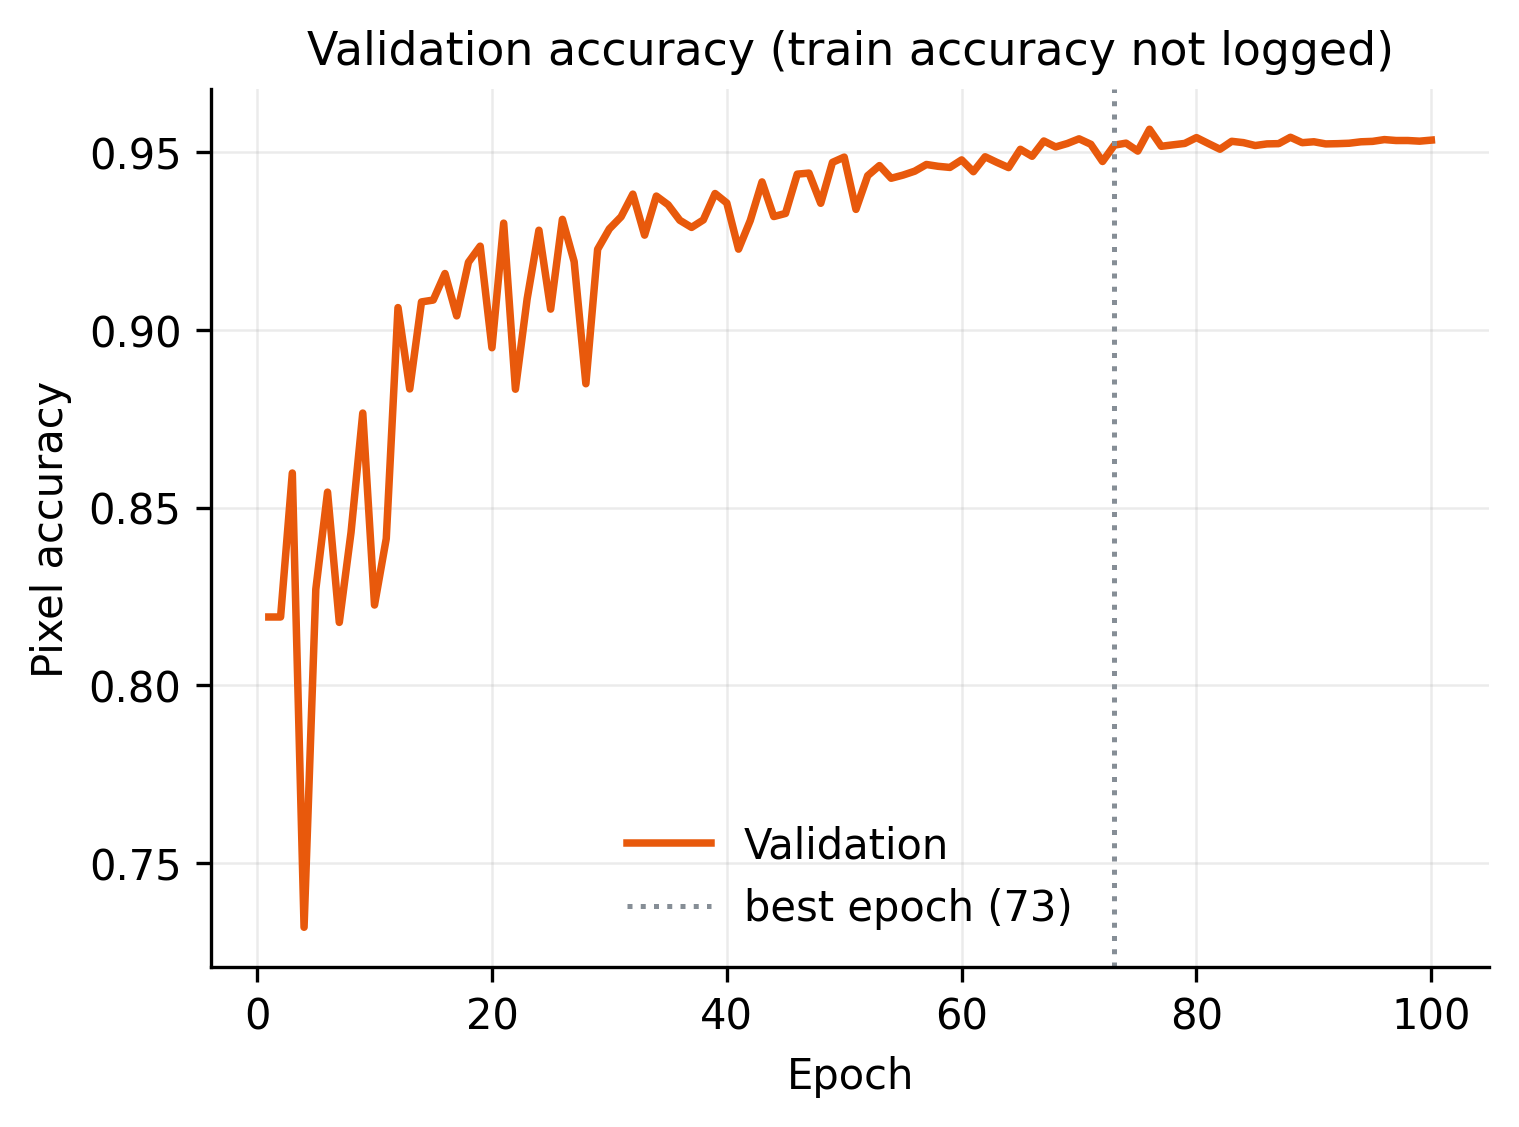

In [25]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_accuracy.png"
display(Image(filename=image_path, width=500))

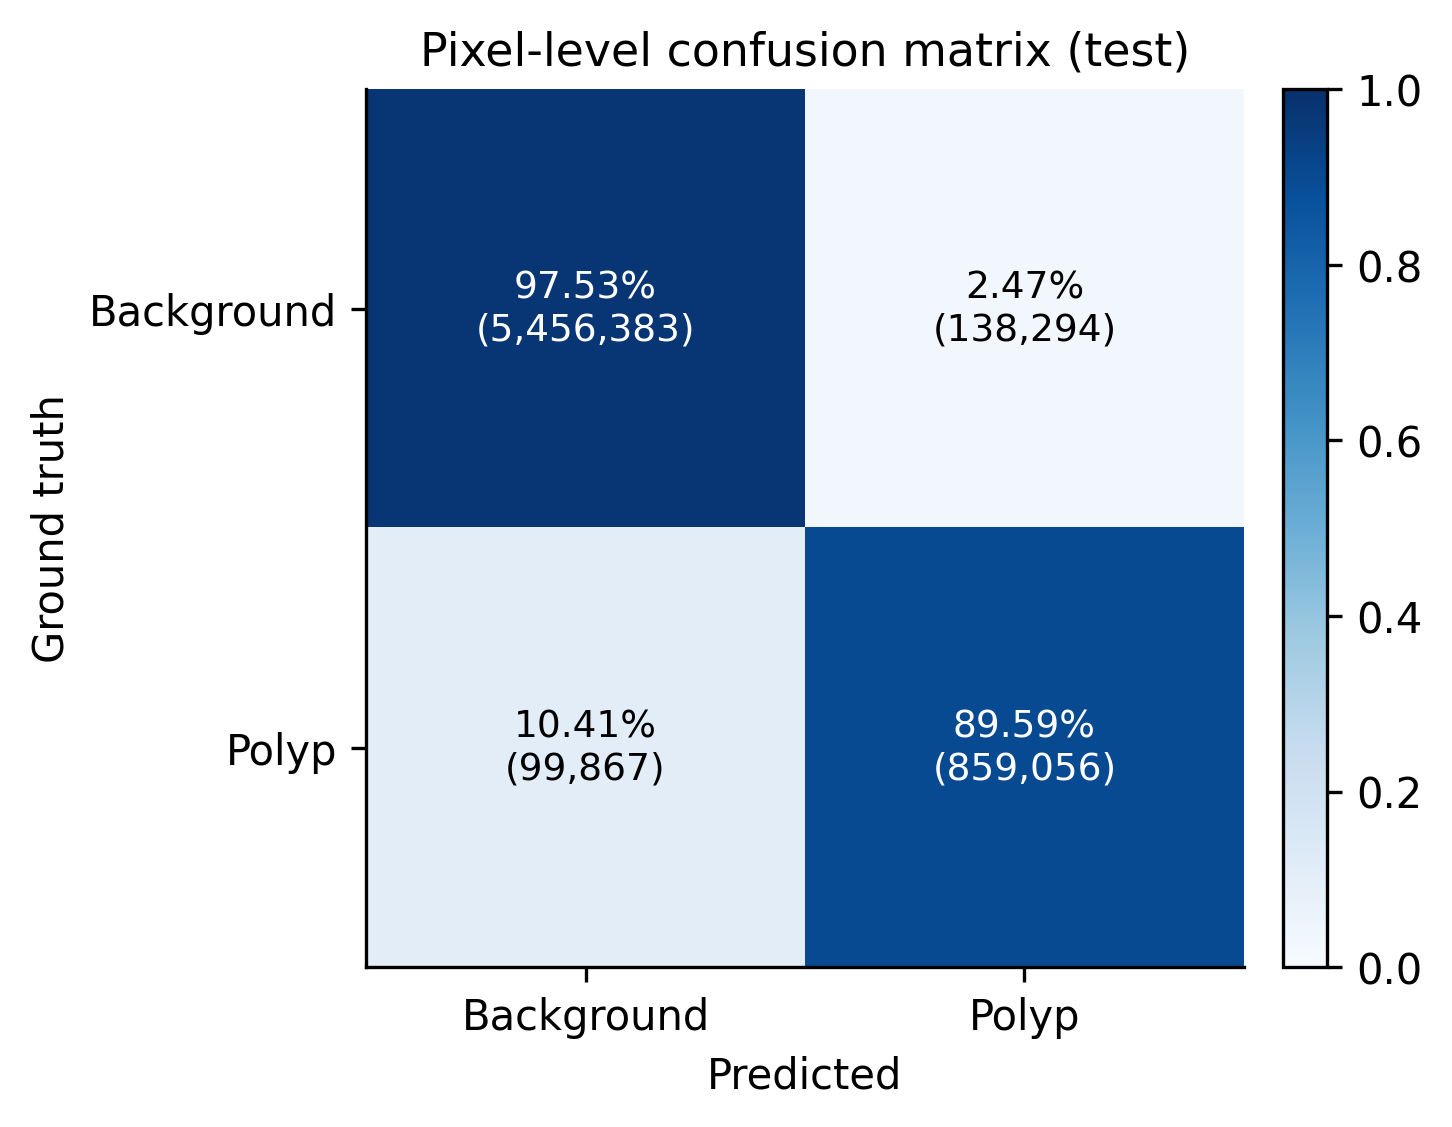

In [26]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_confusion.png"
display(Image(filename=image_path, width=500))

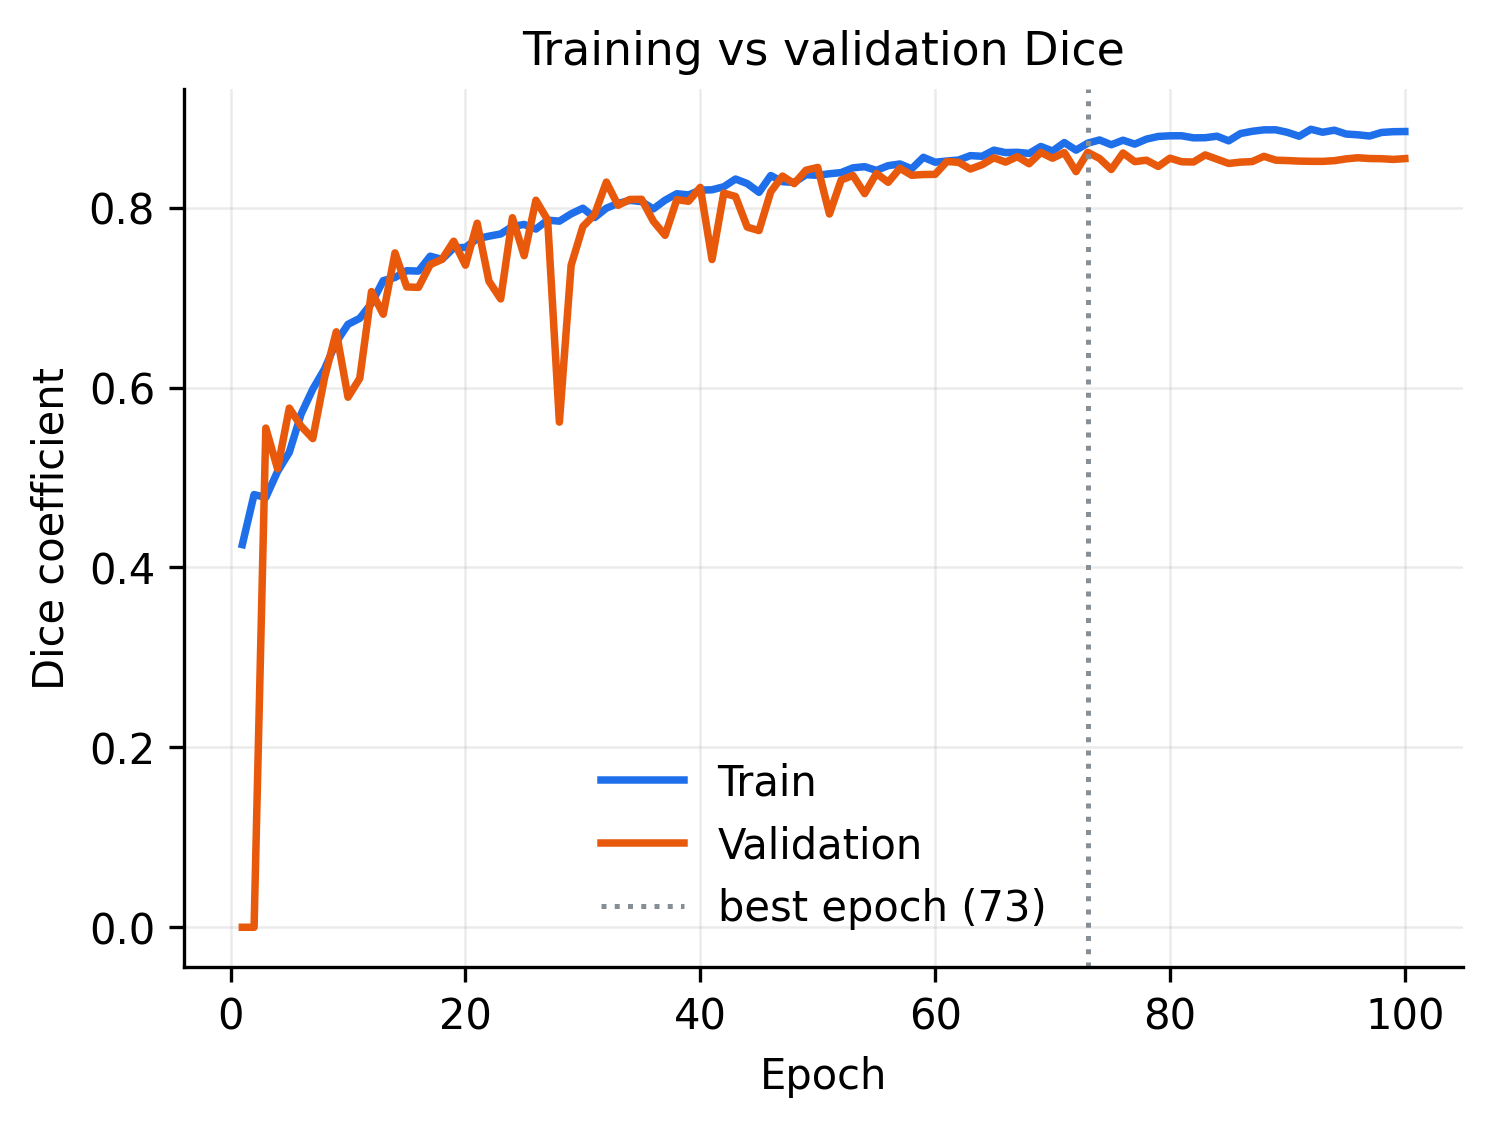

In [28]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_dice.png"
display(Image(filename=image_path, width=500))

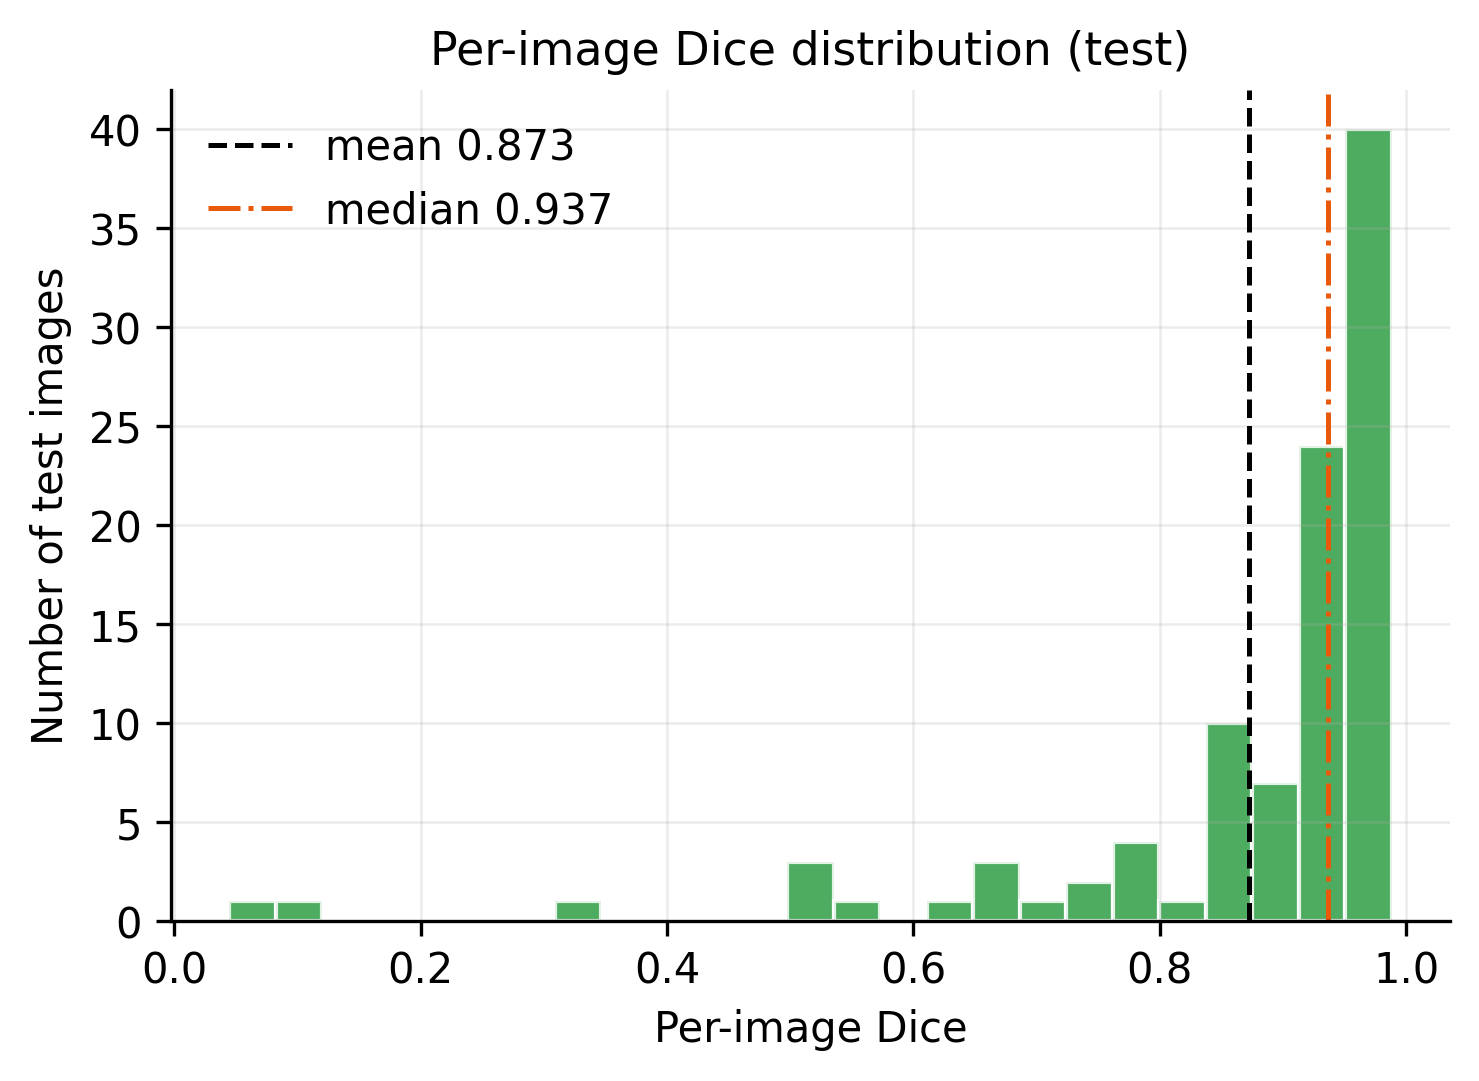

In [29]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_dice_dist.png"
display(Image(filename=image_path, width=500))

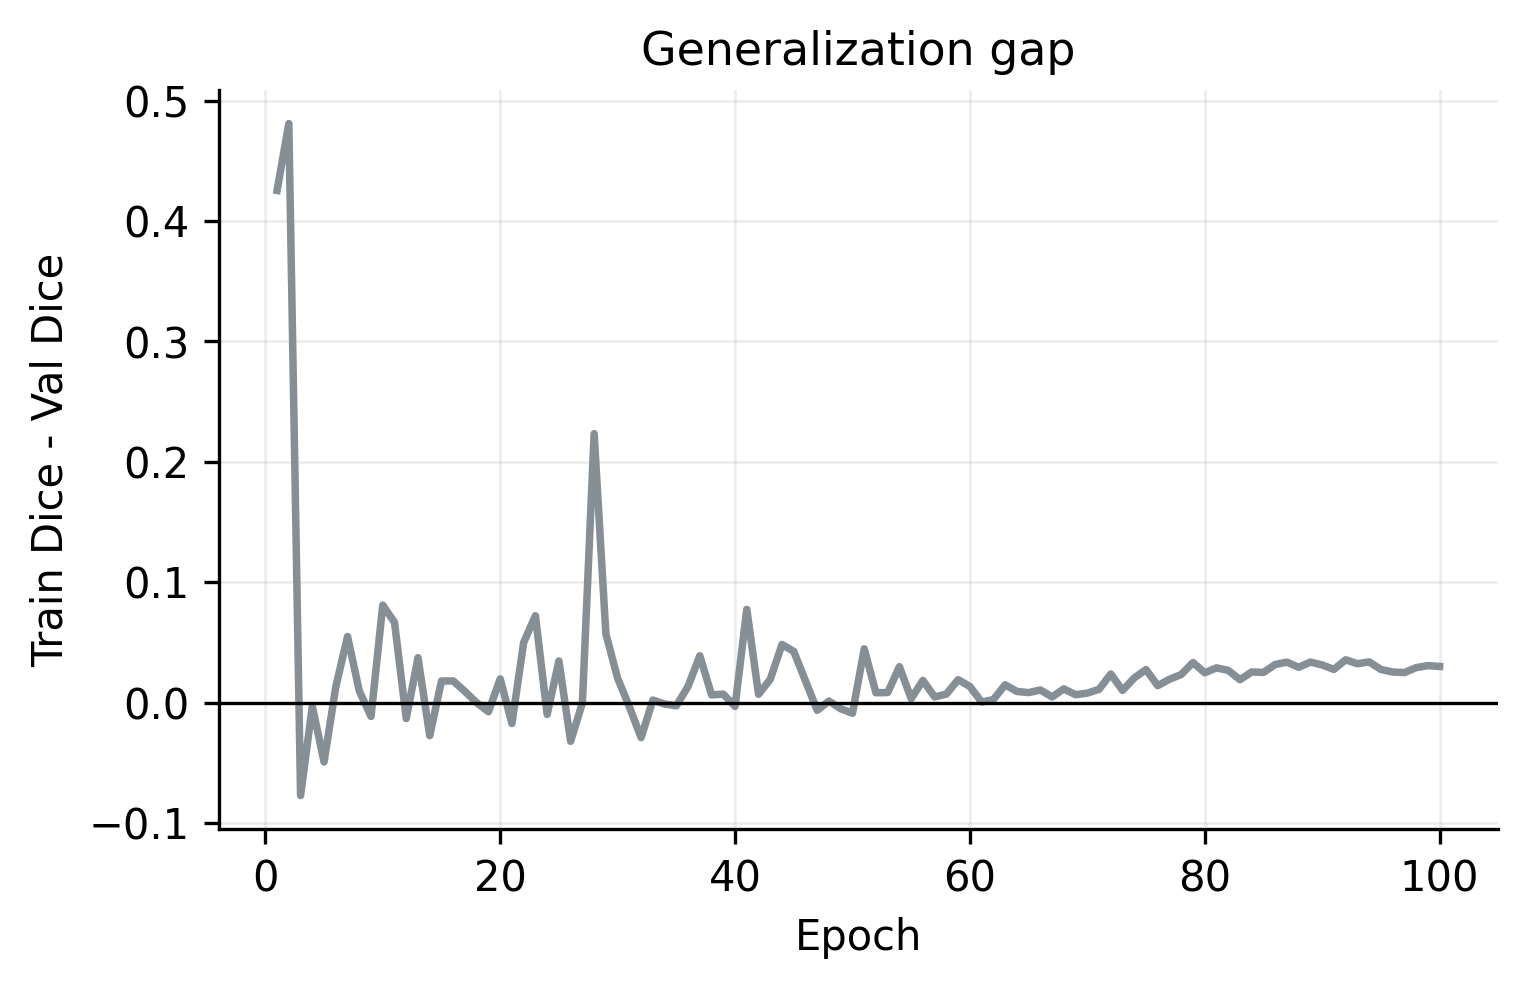

In [30]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_gap.png"
display(Image(filename=image_path, width=500))

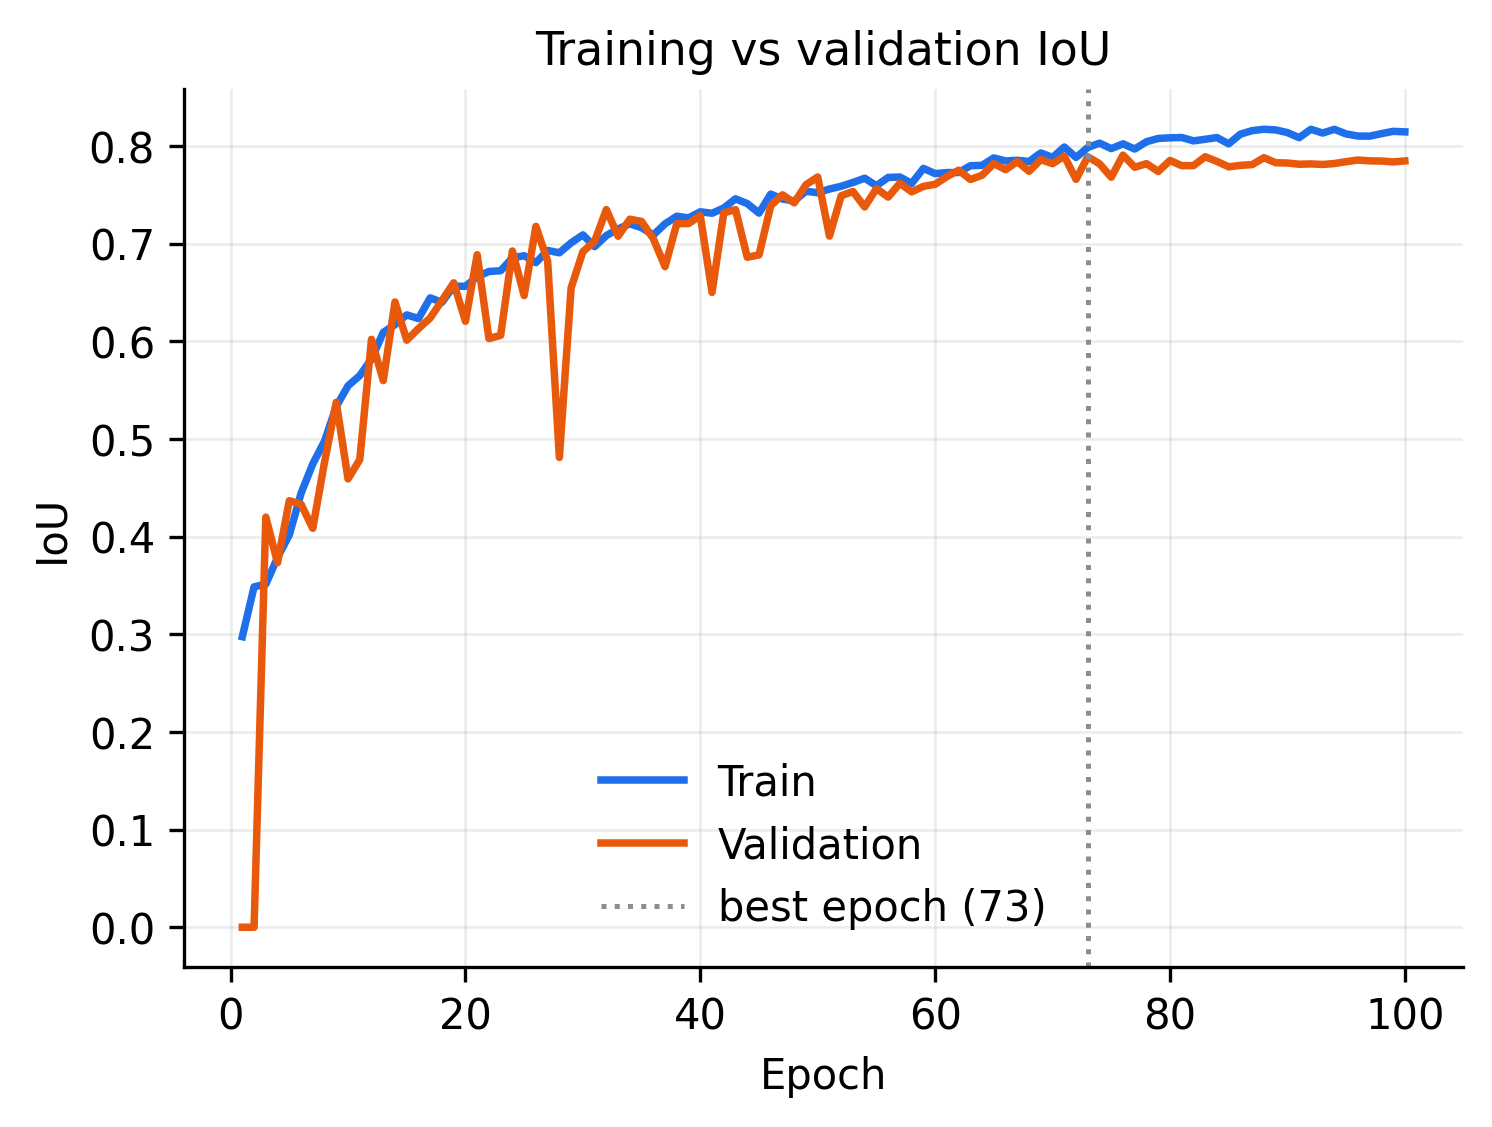

In [31]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_iou.png"
display(Image(filename=image_path, width=500))

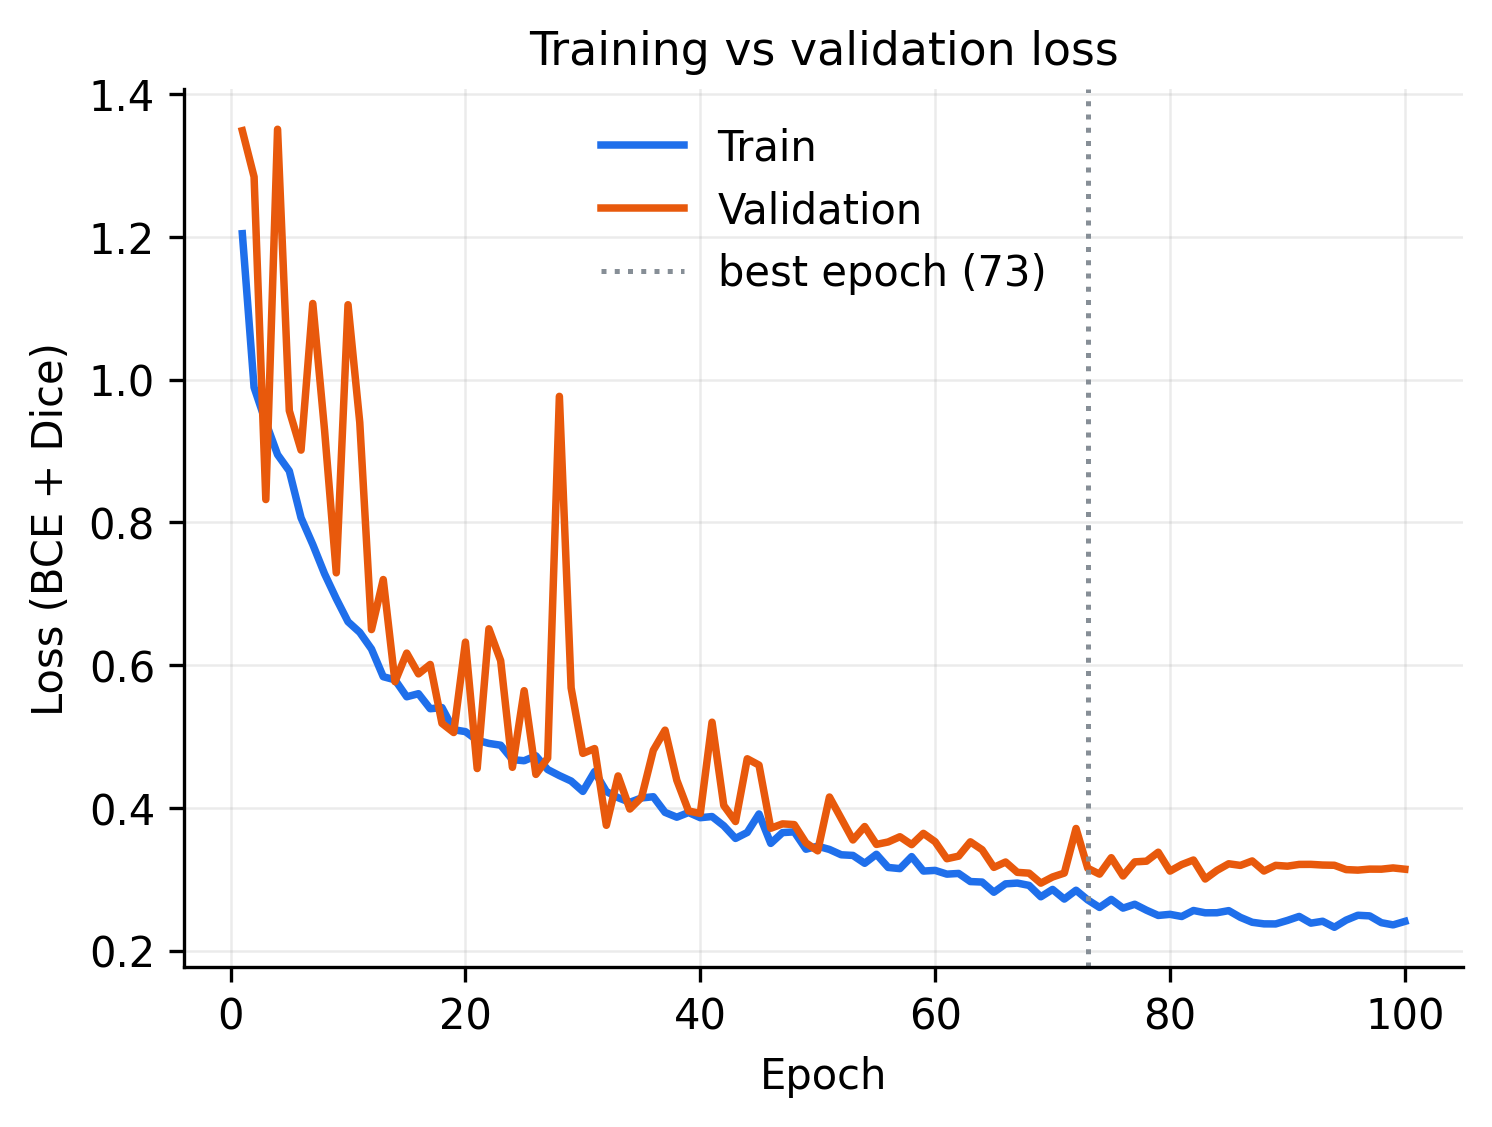

In [32]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_loss.png"
display(Image(filename=image_path, width=500))

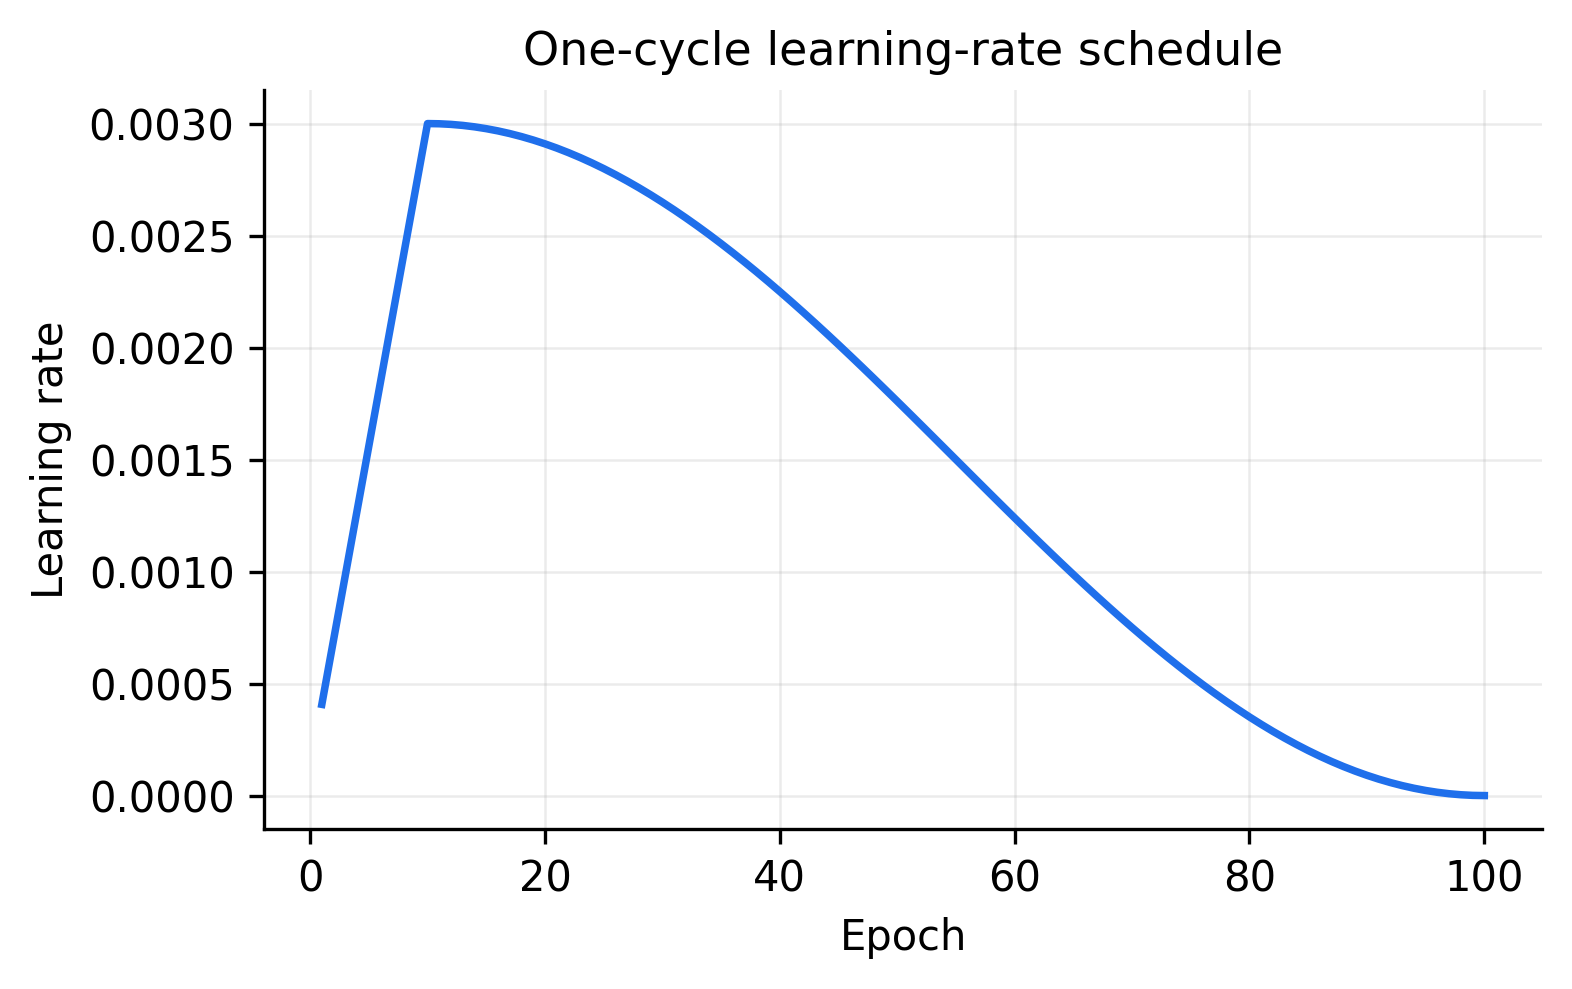

In [33]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_lr.png"
display(Image(filename=image_path, width=500))

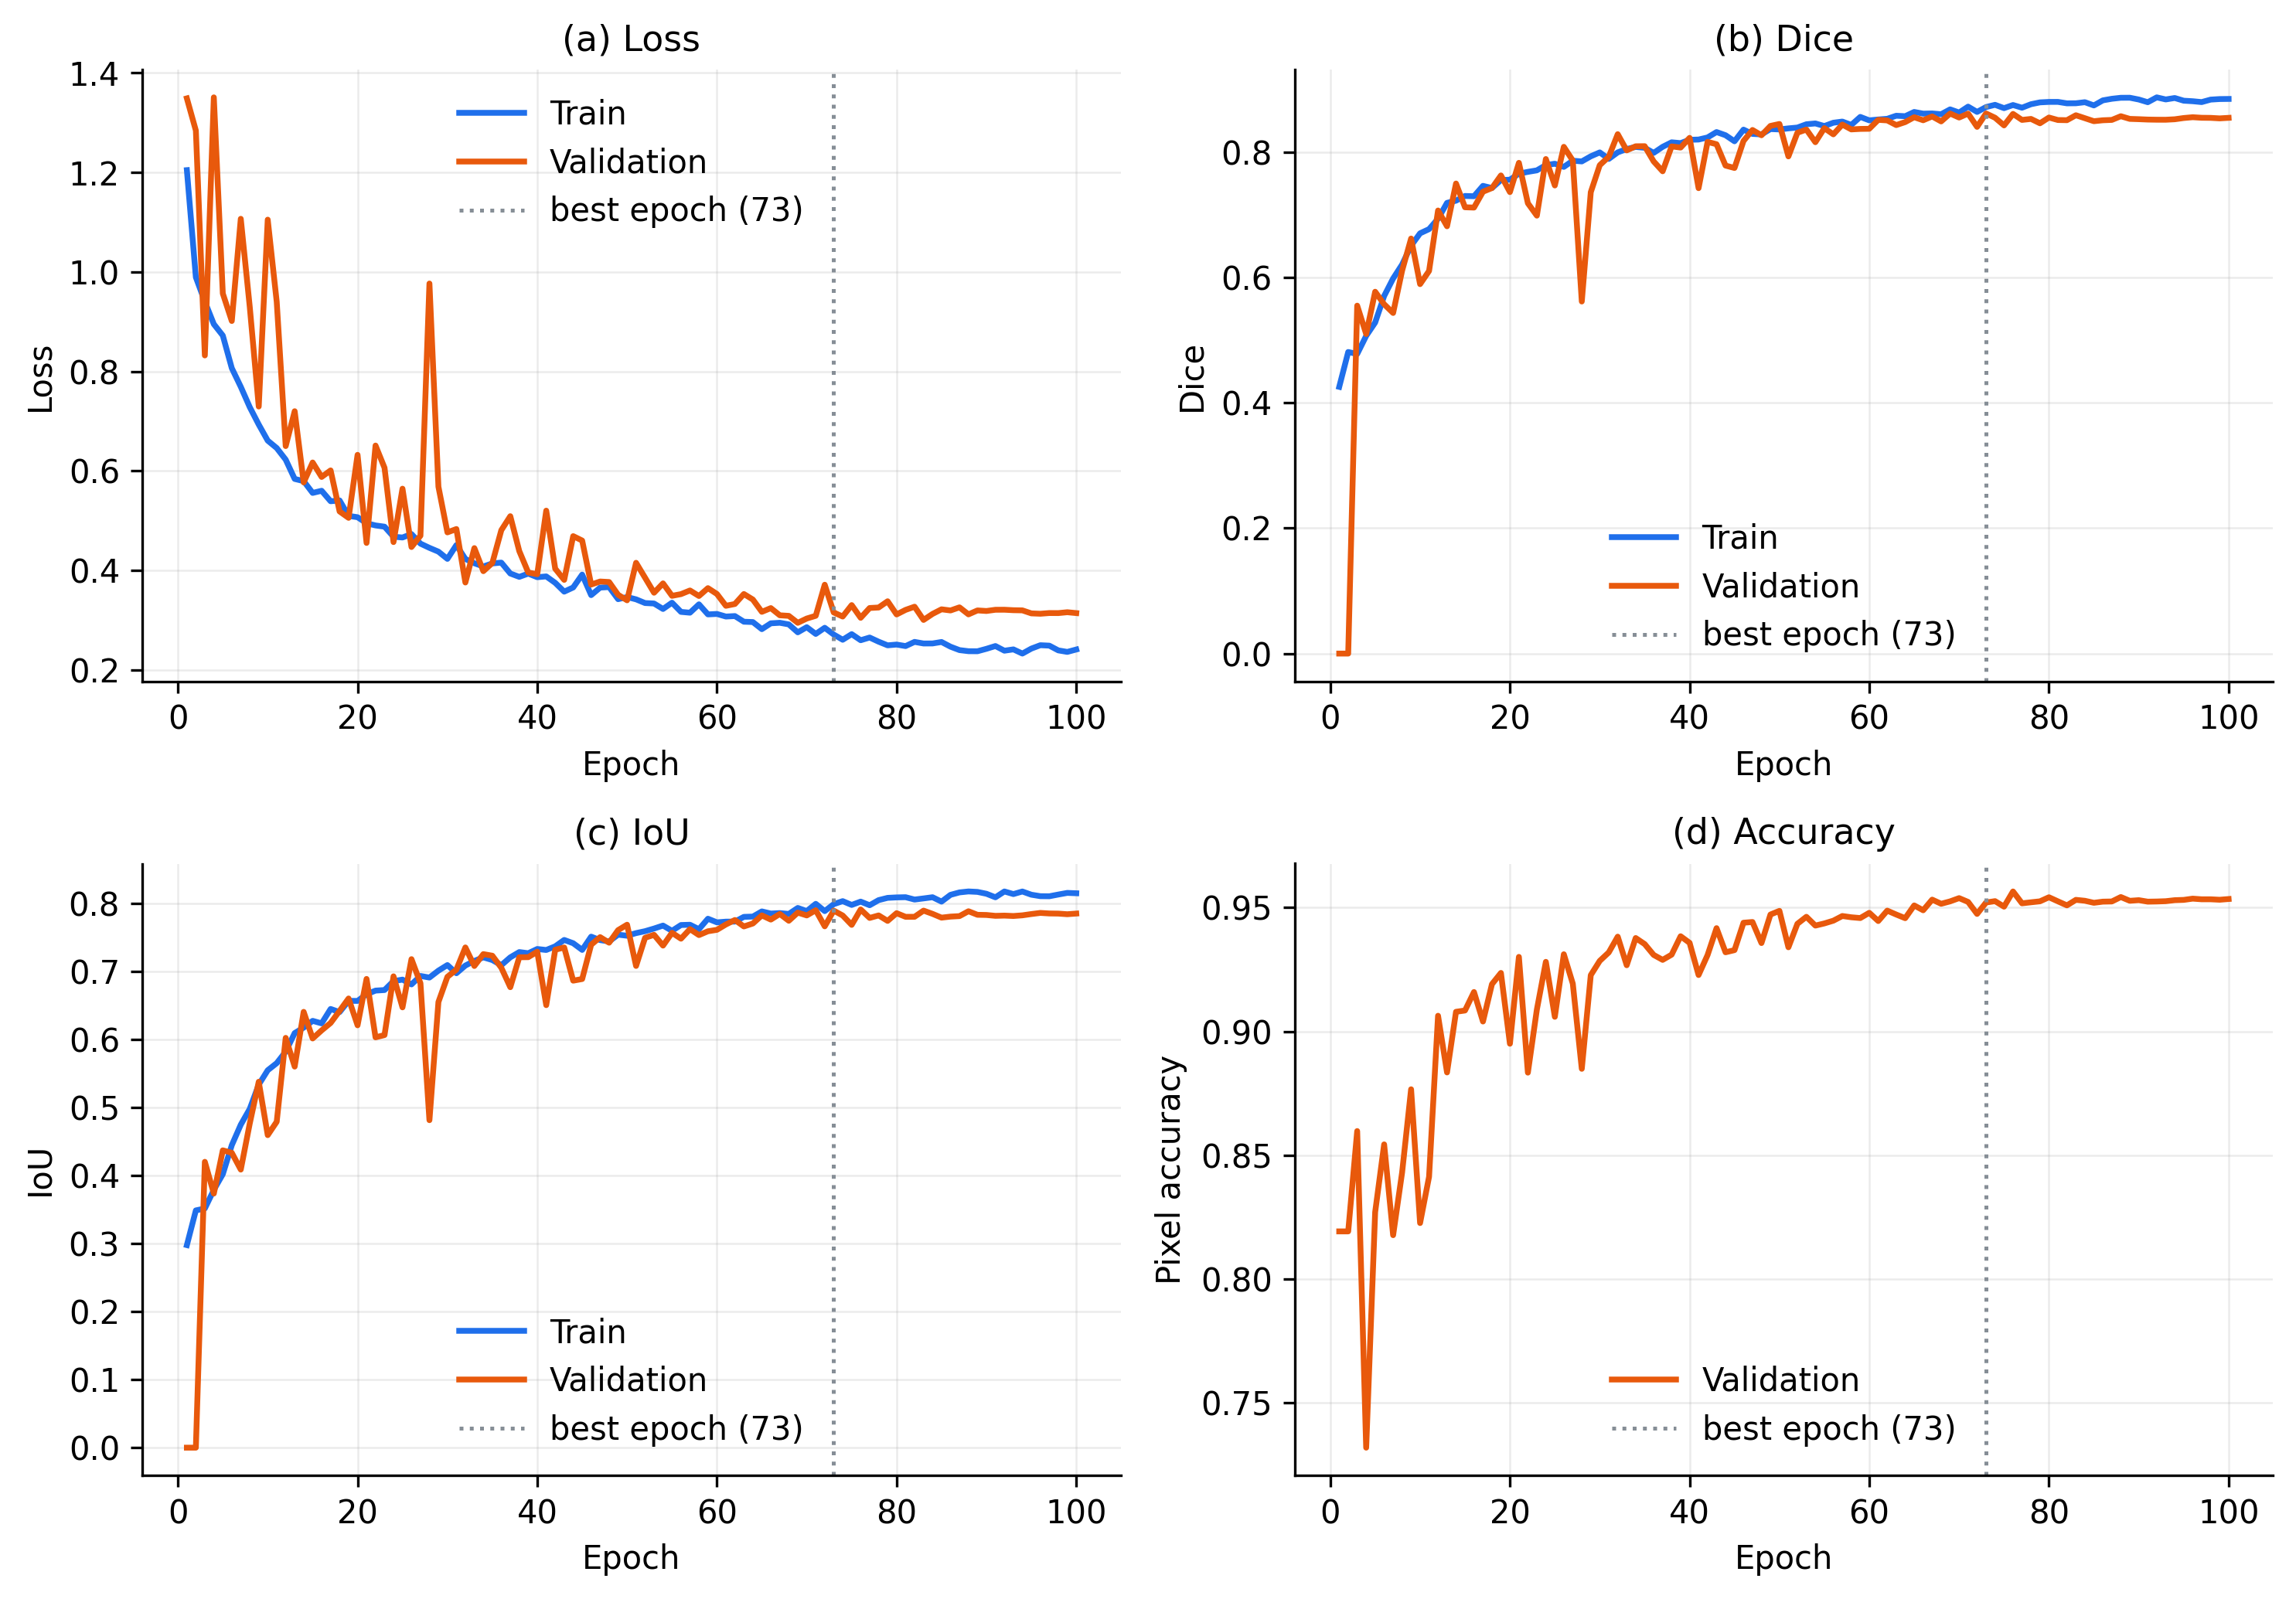

In [35]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_overview.png"
display(Image(filename=image_path, width=800))

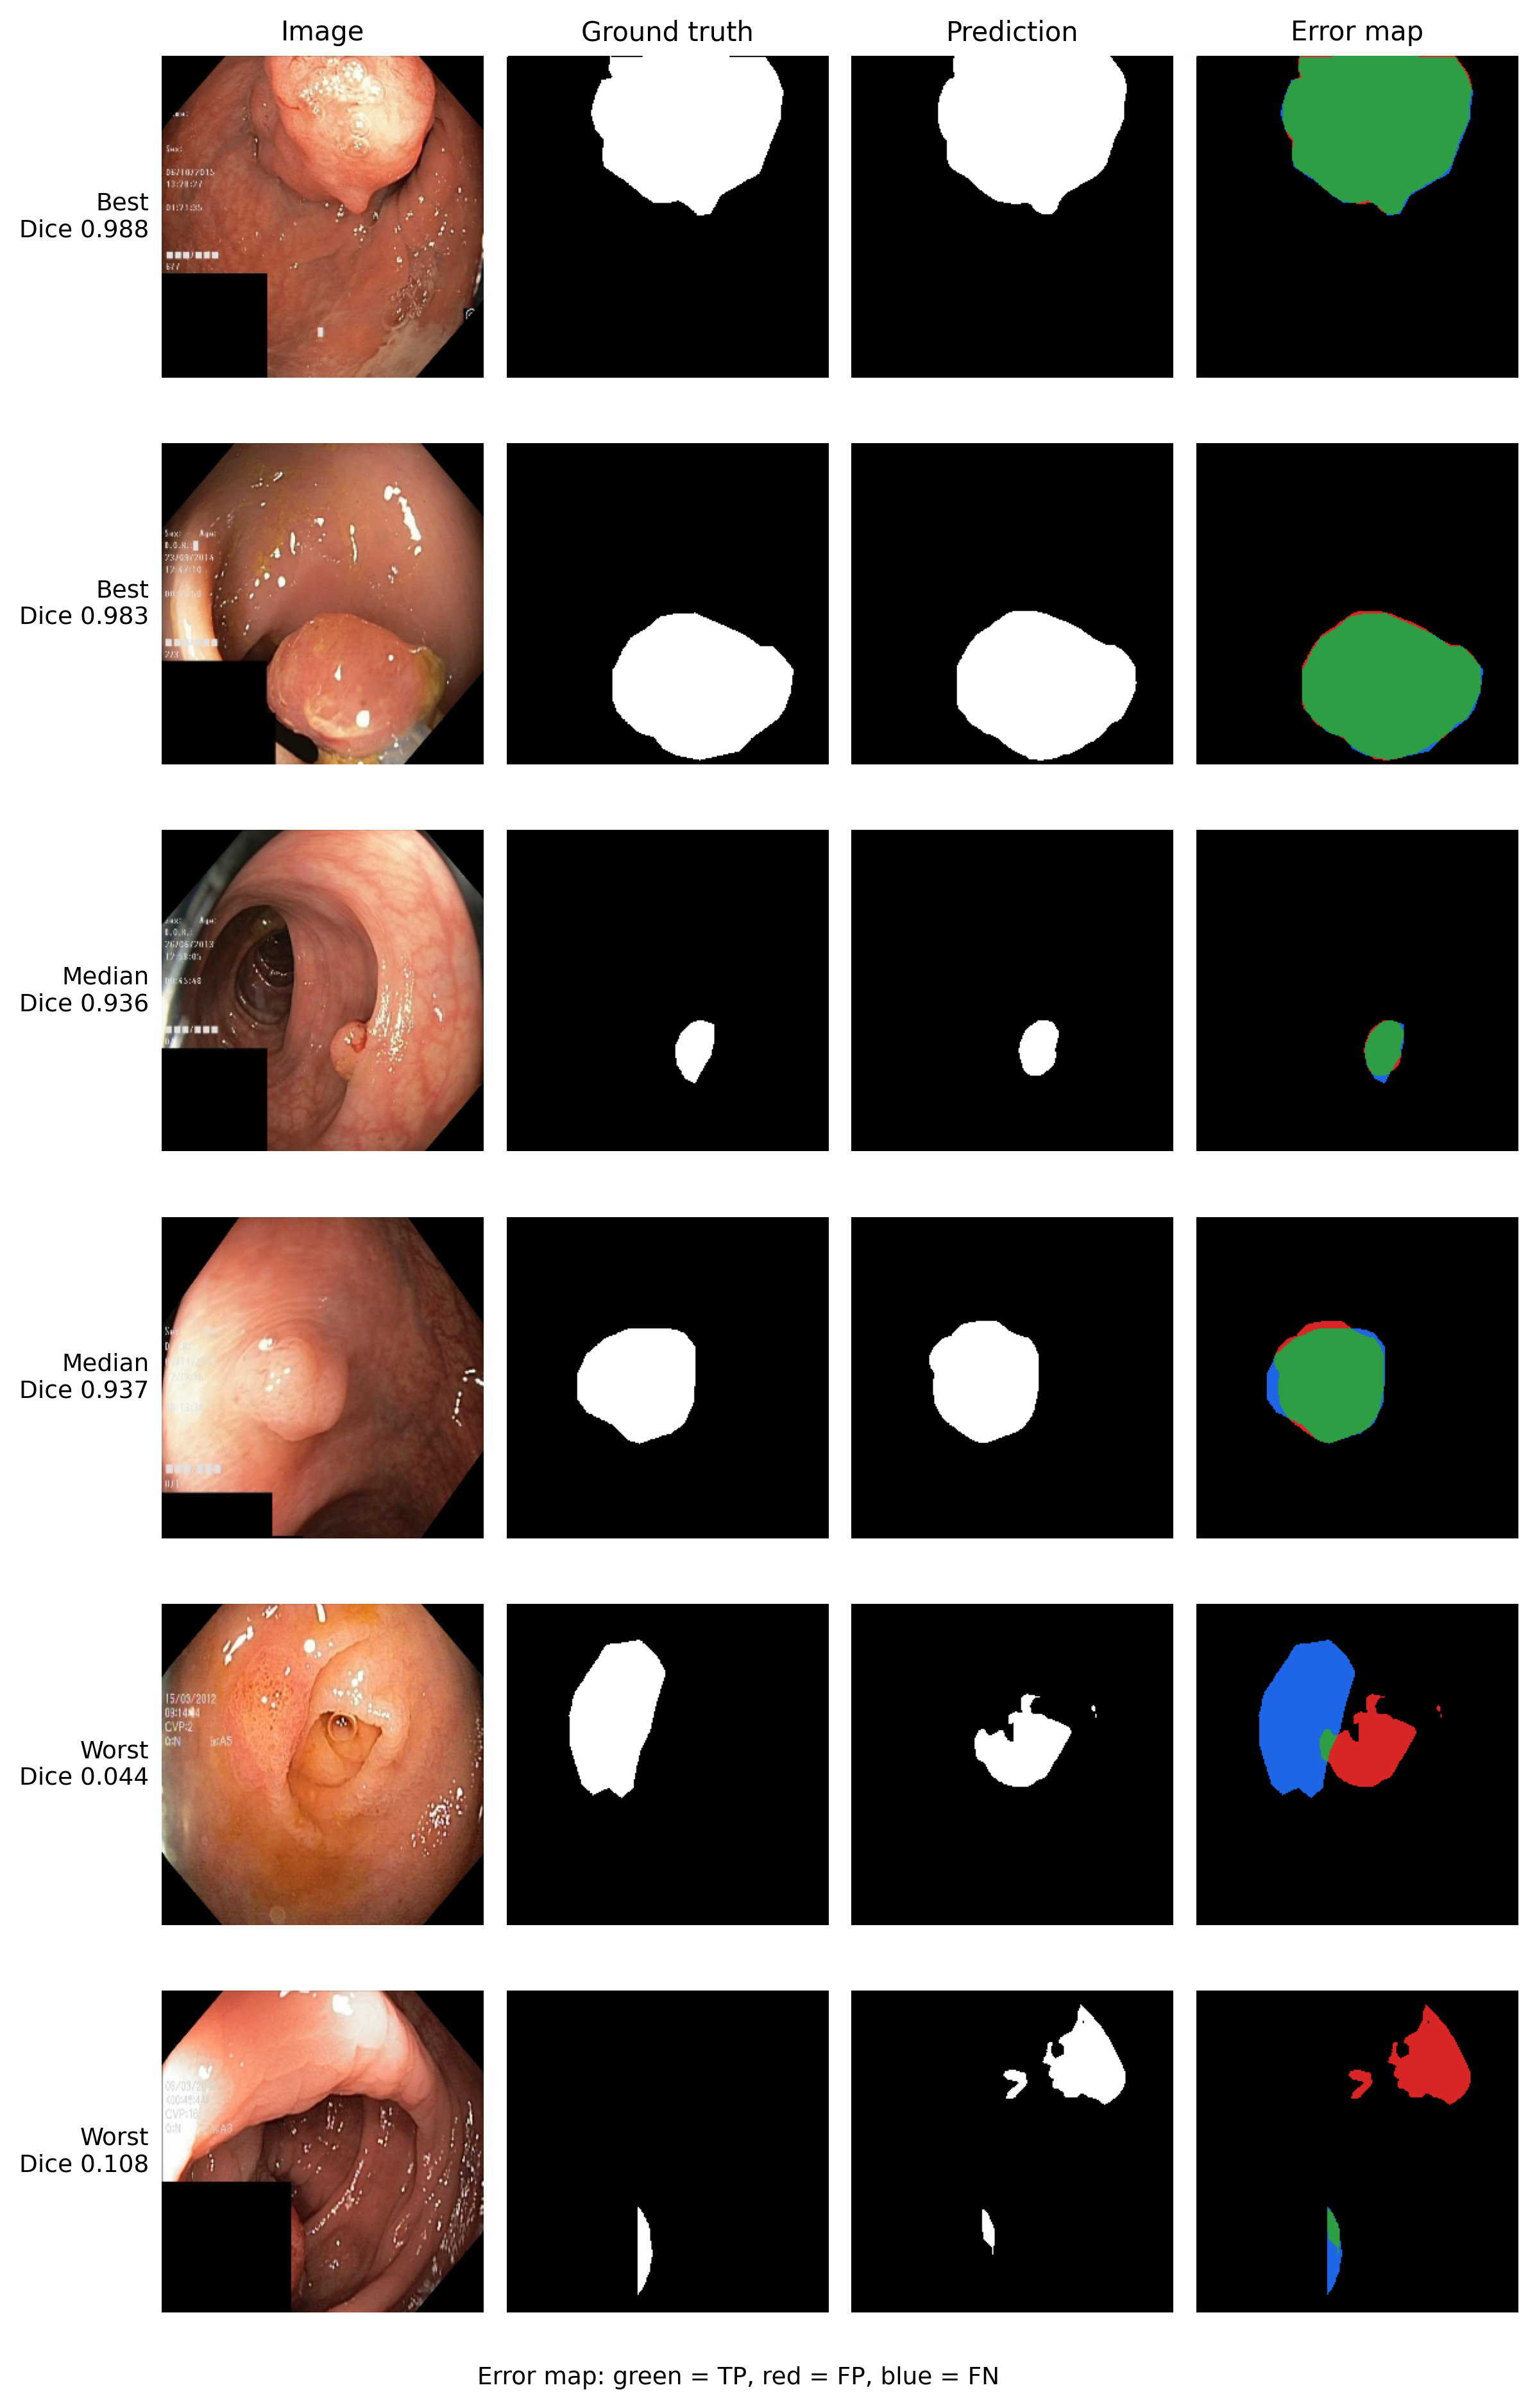

In [41]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_qualitative.png"
display(Image(filename=image_path, width=600))

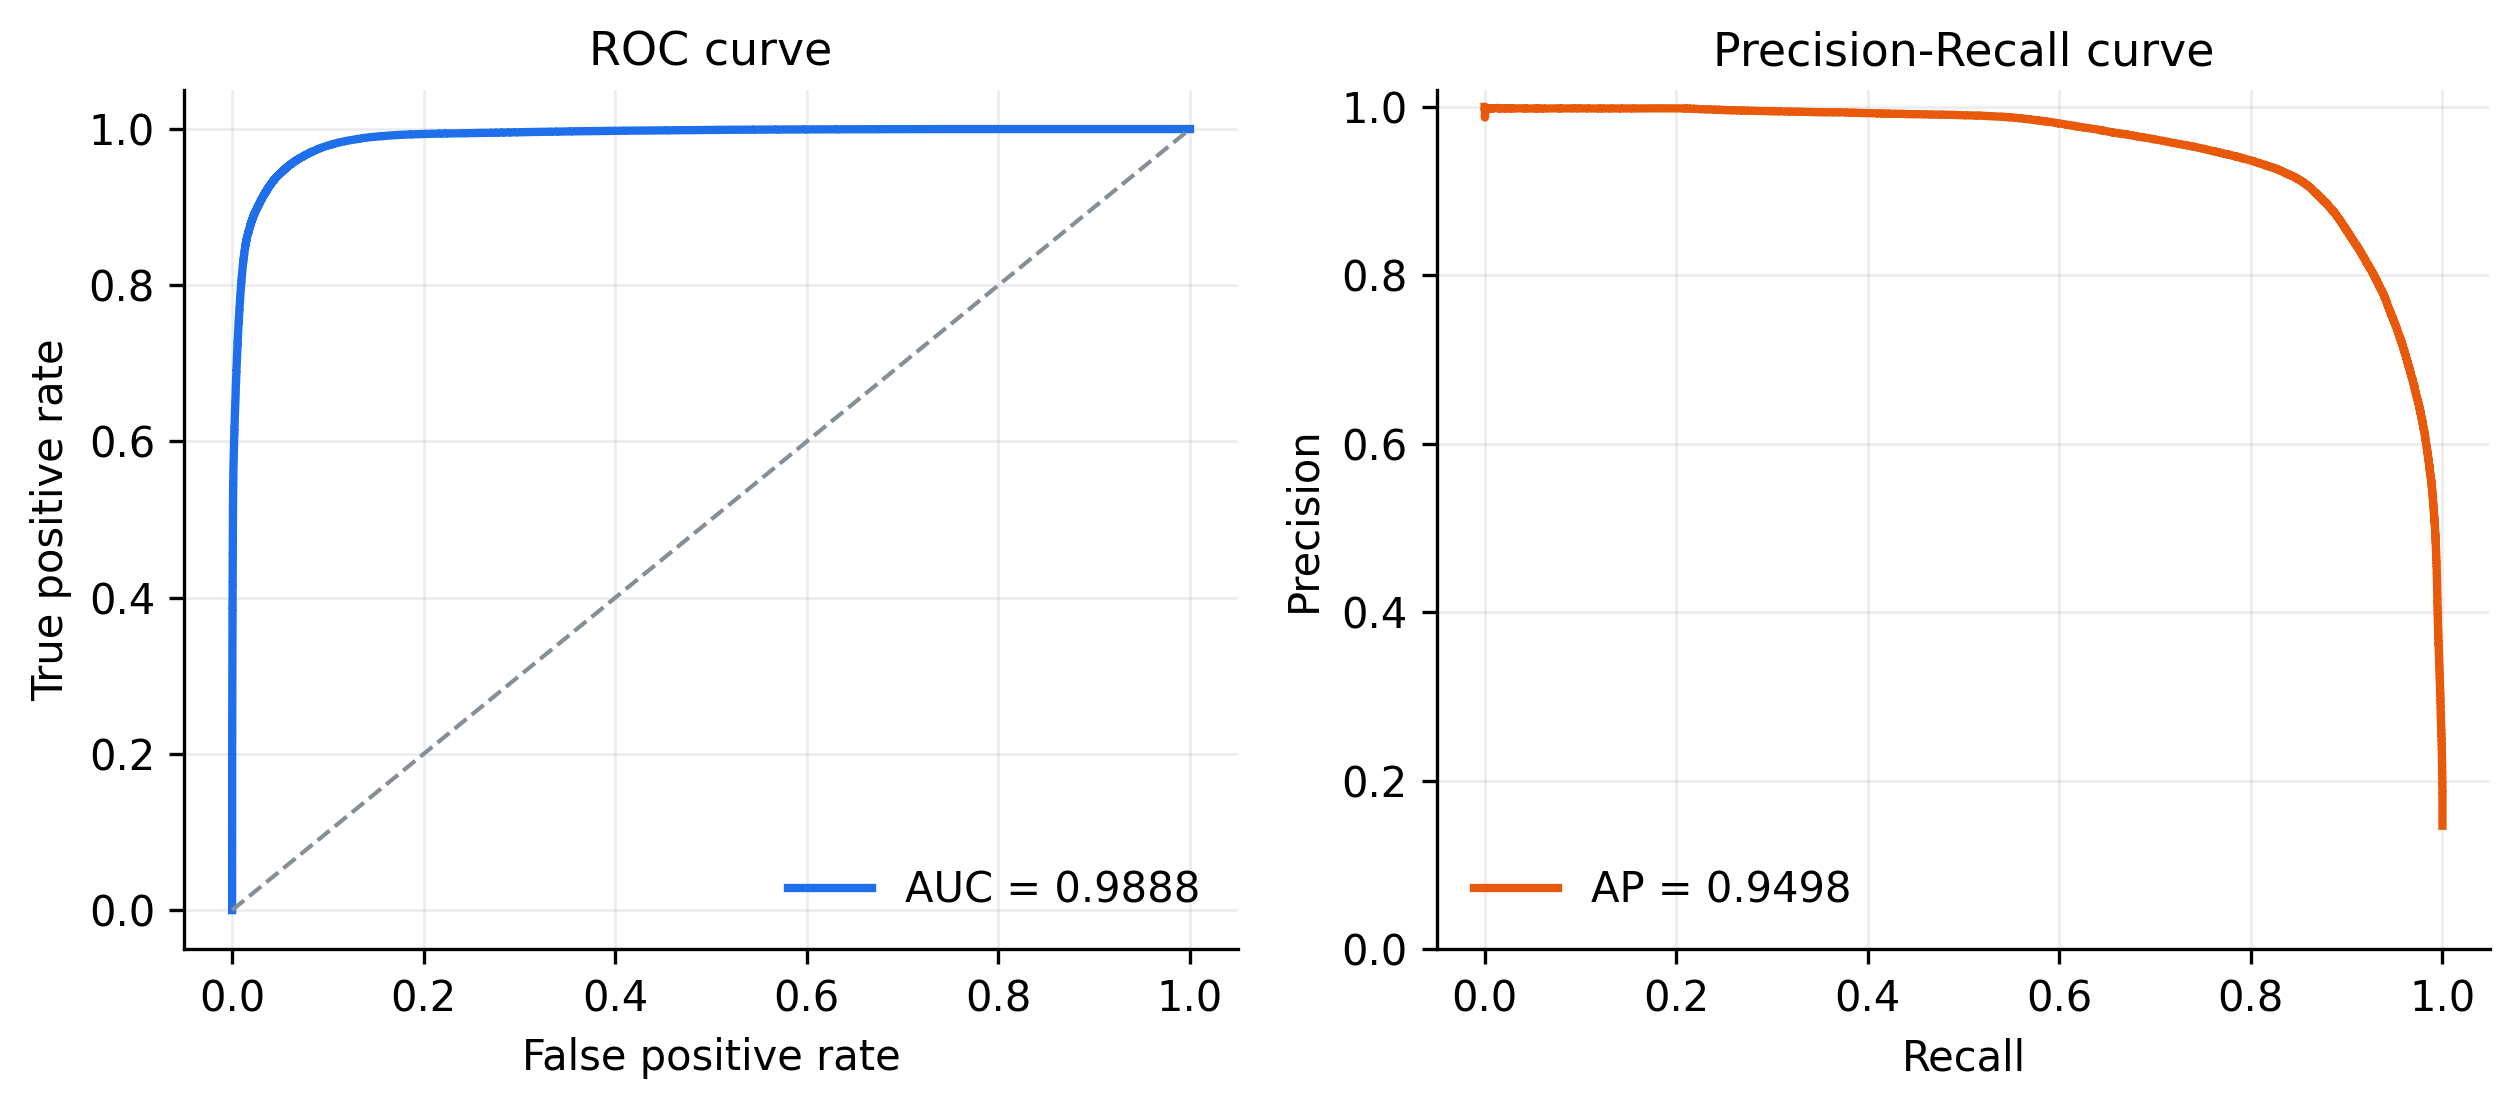

In [42]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_roc_pr.png"
display(Image(filename=image_path, width=800))

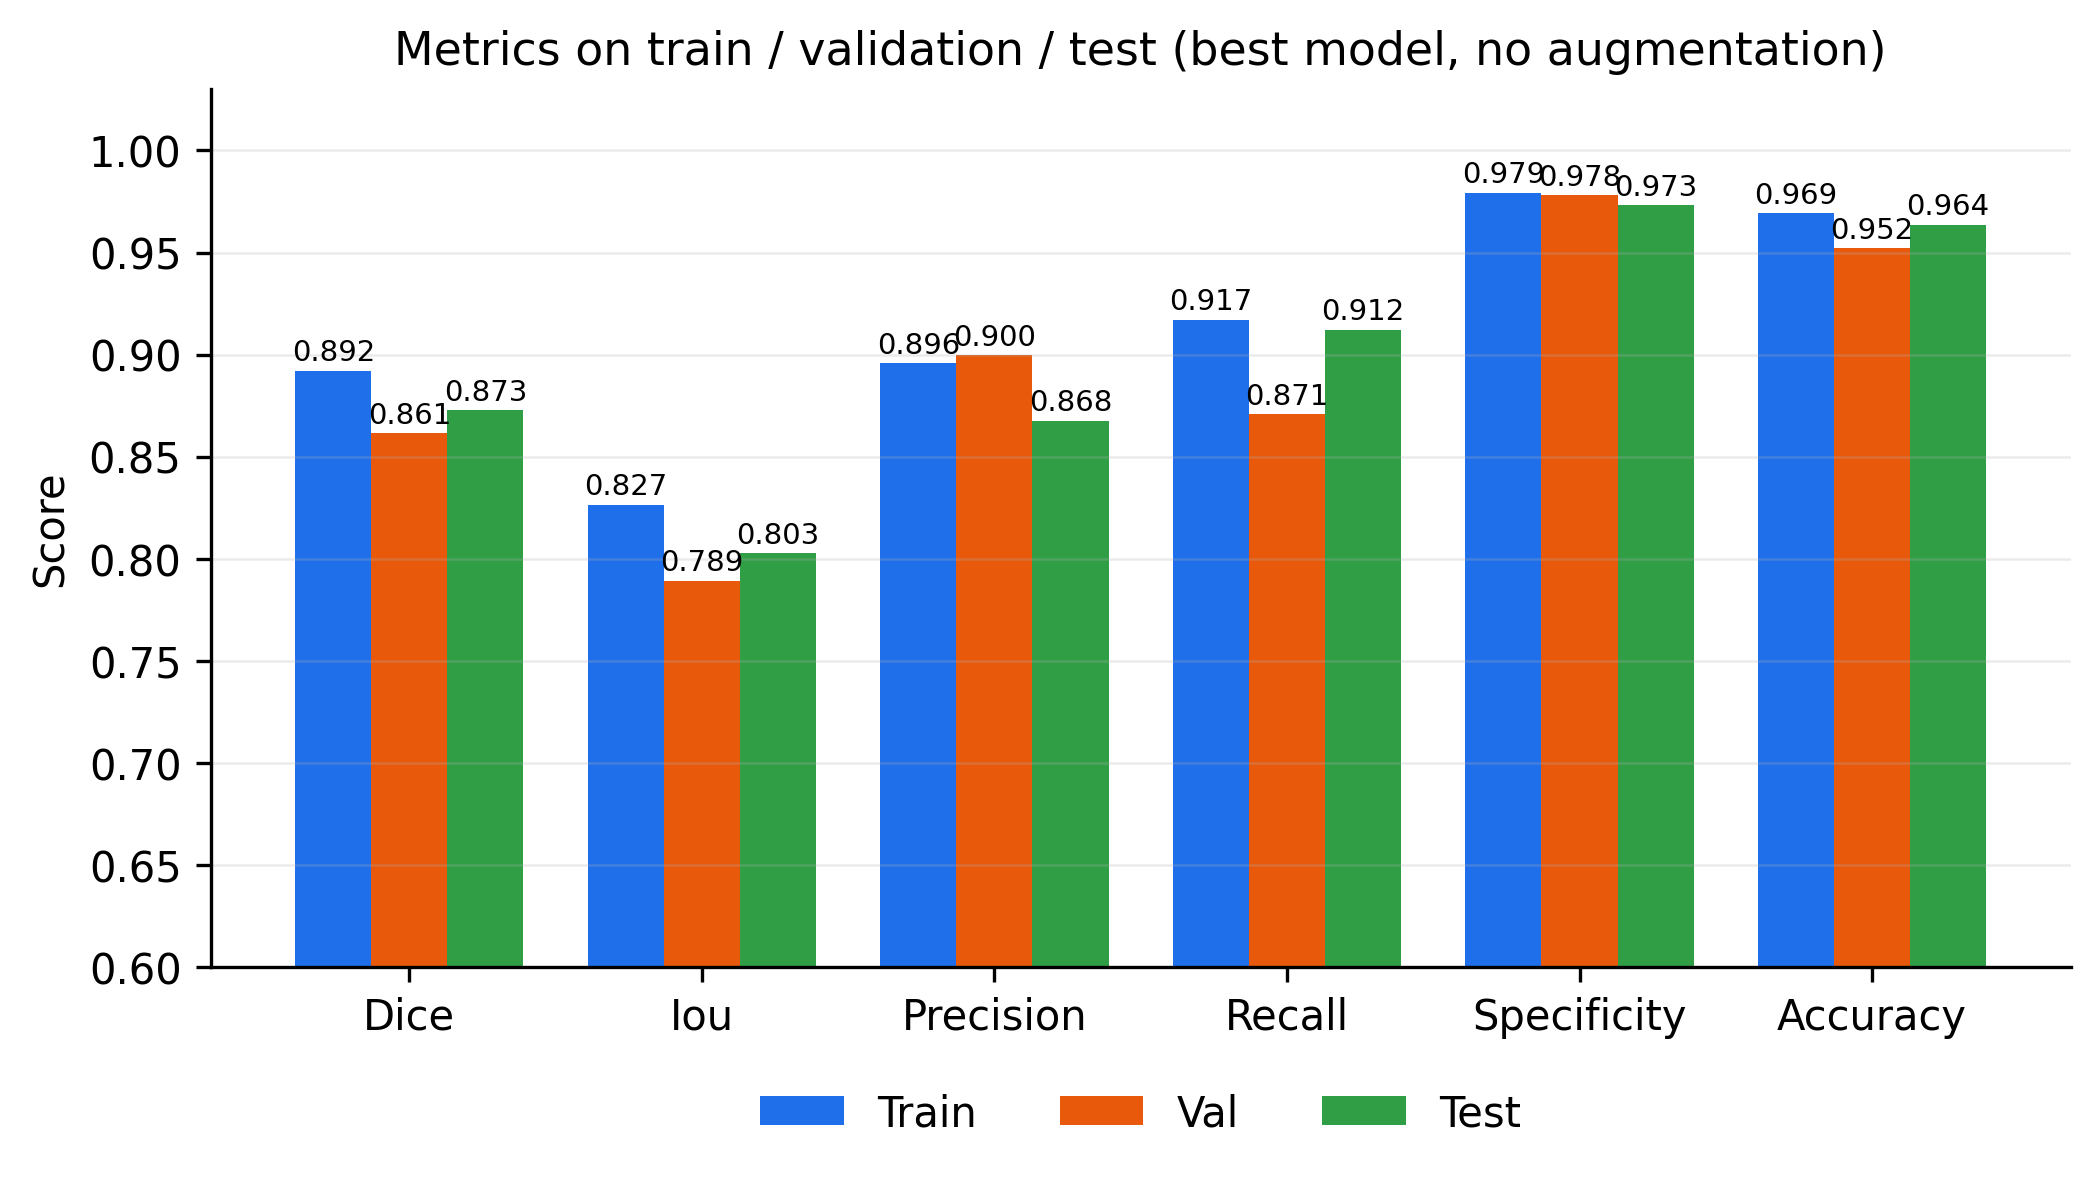

In [39]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_split_metrics.png"
display(Image(filename=image_path, width=800))

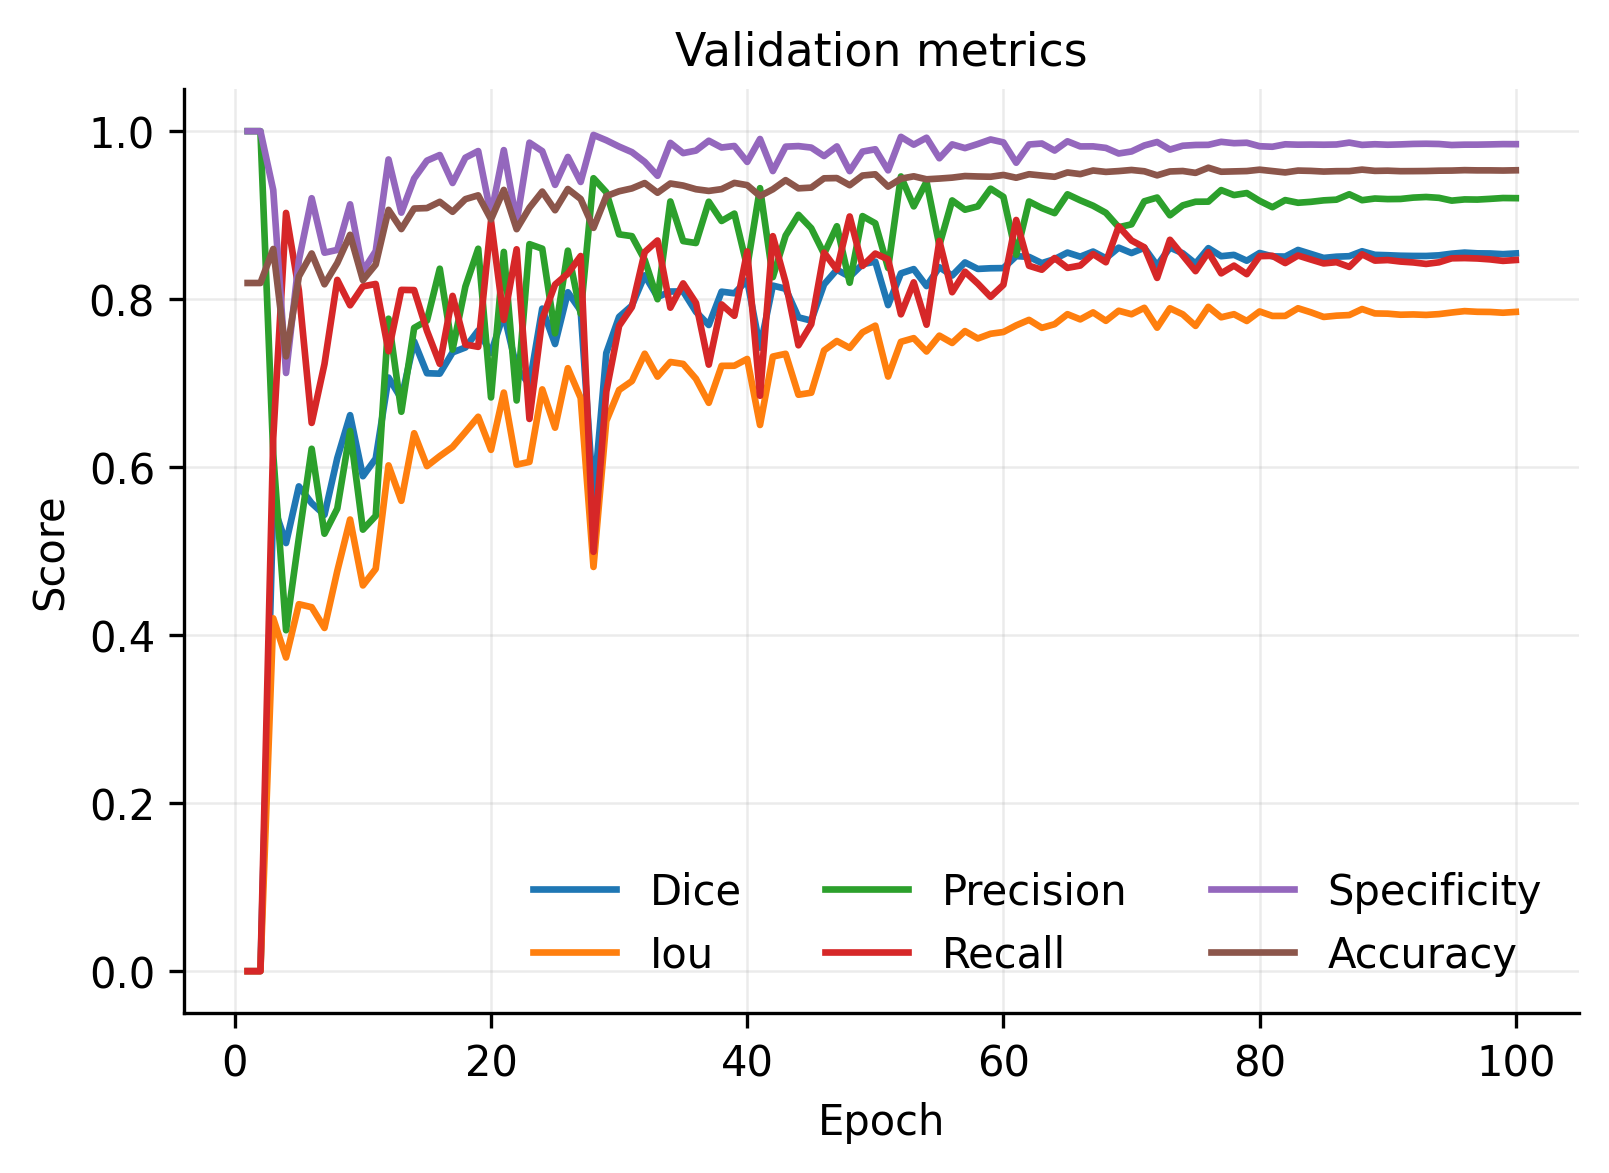

In [40]:
image_path = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/figures/fig_val_metrics.png"
display(Image(filename=image_path, width=800))